# Лабораторная работа 3

1) Полносвязная нейронная сеть ( Fully-Connected Neural Network)

2) Нормализация по мини-батчам (Batch normalization)

3) Dropout

4) Сверточные нейронные сети (Convolutional Networks)

Лабораторные работы можно выполнять с использованием сервиса Google Colaboratory (https://medium.com/deep-learning-turkey/google-colab-free-gpu-tutorial-e113627b9f5d) или на локальном компьютере. 

# Полносвязная нейронная сеть

В данной лабораторной работе необходимо будет реализовать полносвязную нейронную сеть, используя модульный подход. Для каждого  слоя реализации прямого и обратного проходов алгоритма обратного распространения ошибки будут иметь следующий вид:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```



```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

    

In [1]:
import os
import pickle
from time import time
from math import sqrt, ceil

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))


def print_mean_std(x, axis=0):
    print('  means: ', x.mean(axis=axis))
    print('  stds:  ', x.std(axis=axis))
    print()

### Вспомогательные функции

Численный градиент (для проверки обратных проходов) и визуализация весов.

In [2]:
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
    """
    Численный градиент скалярной функции f в точке x (центральная разность).
    x изменяется на месте и потом восстанавливается.
    """
    fx = f(x)
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h
        fxph = f(x)
        x[ix] = oldval - h
        fxmh = f(x)
        x[ix] = oldval

        grad[ix] = (fxph - fxmh) / (2 * h)
        if verbose:
            print(ix, grad[ix])
        it.iternext()
    return grad


def eval_numerical_gradient_array(f, x, df, h=1e-5):
    """
    Численный градиент для функции, которая возвращает массив.
    df - градиент, приходящий сверху (dout), результат - df/dx.
    """
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h
        pos = f(x).copy()
        x[ix] = oldval - h
        neg = f(x).copy()
        x[ix] = oldval

        grad[ix] = np.sum((pos - neg) * df) / (2 * h)
        it.iternext()
    return grad


def visualize_grid(Xs, ubound=255.0, padding=1):
    """
    Склеивает набор картинок (N, H, W, C) в одну сетку,
    каждая картинка нормируется в [0, ubound].
    """
    (N, H, W, C) = Xs.shape
    grid_size = int(ceil(sqrt(N)))
    grid_height = H * grid_size + padding * (grid_size - 1)
    grid_width = W * grid_size + padding * (grid_size - 1)
    grid = np.zeros((grid_height, grid_width, C))
    next_idx = 0
    y0, y1 = 0, H
    for y in range(grid_size):
        x0, x1 = 0, W
        for x in range(grid_size):
            if next_idx < N:
                img = Xs[next_idx]
                low, high = np.min(img), np.max(img)
                grid[y0:y1, x0:x1] = ubound * (img - low) / (high - low)
                next_idx += 1
            x0 += W + padding
            x1 += W + padding
        y0 += H + padding
        y1 += H + padding
    return grid

Загрузите данные из предыдущей лабораторной работы. 

In [ ]:
def load_CIFAR_batch(filename):
    """ один батч CIFAR-10 (10 000 картинок) """
    with open(filename, 'rb') as f:
        datadict = pickle.load(f, encoding='latin1')
        X = datadict['data']
        Y = datadict['labels']
        X = X.reshape(10000, 3, 32, 32).transpose(0, 2, 3, 1).astype('float')
        Y = np.array(Y)
        return X, Y


def load_CIFAR10(ROOT):
    """ весь CIFAR-10: data_batch_1..5 + test_batch """
    xs, ys = [], []
    for b in range(1, 6):
        X, Y = load_CIFAR_batch(os.path.join(ROOT, 'data_batch_%d' % b))
        xs.append(X)
        ys.append(Y)
    Xtr = np.concatenate(xs)
    Ytr = np.concatenate(ys)
    Xte, Yte = load_CIFAR_batch(os.path.join(ROOT, 'test_batch'))
    return Xtr, Ytr, Xte, Yte


def get_CIFAR10_data(cifar10_dir, num_training=49000, num_validation=1000,
                     num_test=1000, subtract_mean=True):
    """
    Загрузка и предобработка как в ЛР 1-2: train/val/test,
    вычитание среднего изображения, каналы вперёд -> (N, 3, 32, 32).
    """
    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    if subtract_mean:
        mean_image = np.mean(X_train, axis=0)
        X_train -= mean_image
        X_val -= mean_image
        X_test -= mean_image

    X_train = X_train.transpose(0, 3, 1, 2).copy()
    X_val = X_val.transpose(0, 3, 1, 2).copy()
    X_test = X_test.transpose(0, 3, 1, 2).copy()

    return {
        'X_train': X_train, 'y_train': y_train,
        'X_val': X_val, 'y_val': y_val,
        'X_test': X_test, 'y_test': y_test,
    }

cifar10_dir = os.path.join('..', '..', 'cifar-10-python', 'cifar-10-batches-py')
data = get_CIFAR10_data(cifar10_dir)
for k, v in data.items():
    print('%s: ' % k, v.shape)

X_train:  (49000, 3, 32, 32)
y_train:  (49000,)
X_val:  (1000, 3, 32, 32)
y_val:  (1000,)
X_test:  (1000, 3, 32, 32)
y_test:  (1000,)


Для полносвязного слоя реализуйте прямой проход (функция affine_forward). Протестируйте свою реализацию. 

In [ ]:
def affine_forward(x, w, b):
    """
    Прямой проход полносвязного слоя.
    """
    N = x.shape[0]
    out = x.reshape(N, -1).dot(w) + b   # каждый пример вытягиваем в вектор длины D
    cache = (x, w, b)
    return out, cache

In [5]:
num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])


print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769849468192957e-10


Для полносвязного слоя реализуйте обратный проход (функция affine_backward). Протестируйте свою реализацию. 

In [ ]:
def affine_backward(dout, cache):
    """
    Обратный проход полносвязного слоя.
    """
    x, w, b = cache
    N = x.shape[0]
    dx = dout.dot(w.T).reshape(x.shape)
    dw = x.reshape(N, -1).T.dot(dout)
    db = np.sum(dout, axis=0)
    return dx, dw, db

In [7]:
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  5.399100368651805e-11
dw error:  9.904211865398145e-11
db error:  2.4122867568119087e-11


Реализуйте прямой проход для слоя активации ReLU (relu_forward) и протестируйте его.

In [8]:
def relu_forward(x):
    """ ReLU: max(0, x) """
    out = np.maximum(0, x)
    cache = x
    return out, cache

In [ ]:
x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


Реализуйте обратный проход для слоя активации ReLU (relu_backward ) и протестируйте его.

In [10]:
def relu_backward(dout, cache):
    """ градиент проходит только там, где вход был > 0 """
    x = cache
    dx = dout * (x > 0)
    return dx

In [ ]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


Ниже приведены реализации прямого и обратного проходов для часто используемых комбинаций слоев. Например, за полносвязным слоем часто следует слой активации. Ознакомьтесь с функциями affine_relu_forward и affine_relu_backward, запустите код ниже и убедитесь, что ошибка порядка e-10 или ниже. 

In [12]:
def affine_relu_forward(x, w, b):
    """ affine -> ReLU """
    a, fc_cache = affine_forward(x, w, b)
    out, relu_cache = relu_forward(a)
    cache = (fc_cache, relu_cache)
    return out, cache


def affine_relu_backward(dout, cache):
    fc_cache, relu_cache = cache
    da = relu_backward(dout, relu_cache)
    dx, dw, db = affine_backward(da, fc_cache)
    return dx, dw, db


def svm_loss(x, y):
    """ multiclass SVM loss и градиент по scores """
    N = x.shape[0]
    correct_class_scores = x[np.arange(N), y]
    margins = np.maximum(0, x - correct_class_scores[:, np.newaxis] + 1.0)
    margins[np.arange(N), y] = 0
    loss = np.sum(margins) / N
    num_pos = np.sum(margins > 0, axis=1)
    dx = np.zeros_like(x)
    dx[margins > 0] = 1
    dx[np.arange(N), y] -= num_pos
    dx /= N
    return loss, dx


def softmax_loss(x, y):
    """ softmax (cross-entropy) loss и градиент по scores """
    shifted_logits = x - np.max(x, axis=1, keepdims=True)
    Z = np.sum(np.exp(shifted_logits), axis=1, keepdims=True)
    log_probs = shifted_logits - np.log(Z)
    probs = np.exp(log_probs)
    N = x.shape[0]
    loss = -np.sum(log_probs[np.arange(N), y]) / N
    dx = probs.copy()
    dx[np.arange(N), y] -= 1
    dx /= N
    return loss, dx

In [ ]:
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_relu_forward and affine_relu_backward:
dx error:  2.299579177309368e-11
dw error:  8.162011105764925e-11
db error:  7.826724021458994e-12


Реализуйте двухслойную полносвязную сеть - класс TwoLayerNet. Проверьте свою реализацию, запустив код ниже. 

In [ ]:
class TwoLayerNet(object):
    """
    Двухслойная сеть: affine - relu - affine - softmax.
    Обучение делает отдельный объект Solver, здесь только loss и градиенты.
    """

    def __init__(self, input_dim=3 * 32 * 32, hidden_dim=100, num_classes=10,
                 weight_scale=1e-3, reg=0.0):
        self.params = {}
        self.reg = reg

        self.params['W1'] = weight_scale * np.random.randn(input_dim, hidden_dim)
        self.params['b1'] = np.zeros(hidden_dim)
        self.params['W2'] = weight_scale * np.random.randn(hidden_dim, num_classes)
        self.params['b2'] = np.zeros(num_classes)

    def loss(self, X, y=None):
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']

        # прямой проход
        h, cache1 = affine_relu_forward(X, W1, b1)
        scores, cache2 = affine_forward(h, W2, b2)

        if y is None:
            return scores

        loss, grads = 0, {}
        data_loss, dscores = softmax_loss(scores, y)
        # L2 с множителем 0.5, чтобы производная была просто reg * W
        reg_loss = 0.5 * self.reg * (np.sum(W1 * W1) + np.sum(W2 * W2))
        loss = data_loss + reg_loss

        # обратный проход
        dh, grads['W2'], grads['b2'] = affine_backward(dscores, cache2)
        _, grads['W1'], grads['b1'] = affine_relu_backward(dh, cache1)
        grads['W2'] += self.reg * W2
        grads['W1'] += self.reg * W1

        return loss, grads

In [ ]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray
(
  [
   [11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]
  ]
)
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0
W1 relative error: 1.83e-08
W2 relative error: 3.12e-10
b1 relative error: 9.83e-09
b2 relative error: 4.33e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 2.53e-07
W2 relative error: 2.85e-08
b1 relative error: 1.56e-08
b2 relative error: 7.76e-10


Ознакомьтесь с API для обучения и тестирования моделей - классом Solver. Используйте экземпляр класса Solver для обучения двухслойной полносвязной сети. Необходимо достичь минимум 50% верно классифицированных объектов на валидационном наборе. 

Класс `Solver` (из solver.py) и простейшее правило обновления `sgd` (из optim.py). Остальные правила обновления
(`sgd_momentum`, `rmsprop`, `adam`) реализованы ниже. Solver ищет функцию обновления по имени, поэтому достаточно,
чтобы она была определена к моменту создания Solver.

In [16]:
def sgd(w, dw, config=None):
    """ обычный SGD: w = w - lr * dw """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-2)

    w -= config['learning_rate'] * dw
    return w, config


class Solver(object):
    """
    Обучение модели мини-батчевым градиентным спуском.

    Модель должна иметь:
    - model.params - словарь {имя параметра: массив};
    - model.loss(X, y) - при y=None возвращает scores, иначе (loss, grads).

    data - словарь с ключами X_train, y_train, X_val, y_val.

    Необязательные параметры:
    - update_rule: имя правила обновления ('sgd', 'sgd_momentum', 'rmsprop', 'adam');
    - optim_config: гиперпараметры правила обновления (learning_rate и т.д.);
    - lr_decay: во сколько раз уменьшать learning rate после каждой эпохи;
    - batch_size: размер мини-батча;
    - num_epochs: число эпох;
    - print_every: как часто печатать loss;
    - verbose: печатать ли процесс обучения;
    - num_train_samples: на скольких объектах train считать accuracy (None - на всех);
    - num_val_samples: на скольких объектах val считать accuracy (None - на всех).

    После train() в model.params лежат параметры с лучшей accuracy на валидации,
    а история хранится в loss_history, train_acc_history, val_acc_history.
    """

    def __init__(self, model, data, **kwargs):
        self.model = model
        self.X_train = data['X_train']
        self.y_train = data['y_train']
        self.X_val = data['X_val']
        self.y_val = data['y_val']

        self.update_rule = kwargs.pop('update_rule', 'sgd')
        self.optim_config = kwargs.pop('optim_config', {})
        self.lr_decay = kwargs.pop('lr_decay', 1.0)
        self.batch_size = kwargs.pop('batch_size', 100)
        self.num_epochs = kwargs.pop('num_epochs', 10)
        self.num_train_samples = kwargs.pop('num_train_samples', 1000)
        self.num_val_samples = kwargs.pop('num_val_samples', None)
        self.print_every = kwargs.pop('print_every', 10)
        self.verbose = kwargs.pop('verbose', True)

        if len(kwargs) > 0:
            extra = ', '.join('"%s"' % k for k in list(kwargs.keys()))
            raise ValueError('Unrecognized arguments %s' % extra)

        # правило обновления ищем среди функций, объявленных в блокноте
        rule = globals().get(self.update_rule)
        if not callable(rule):
            raise ValueError('Invalid update_rule "%s"' % self.update_rule)
        self.update_rule = rule

        self._reset()

    def _reset(self):
        self.epoch = 0
        self.best_val_acc = 0
        self.best_params = {}
        self.loss_history = []
        self.train_acc_history = []
        self.val_acc_history = []

        # у каждого параметра свой config (там хранятся velocity, cache, m, v ...)
        self.optim_configs = {}
        for p in self.model.params:
            d = {k: v for k, v in self.optim_config.items()}
            self.optim_configs[p] = d

    def _step(self):
        """ один шаг: мини-батч -> loss и градиенты -> обновление параметров """
        num_train = self.X_train.shape[0]
        batch_mask = np.random.choice(num_train, self.batch_size)
        X_batch = self.X_train[batch_mask]
        y_batch = self.y_train[batch_mask]

        loss, grads = self.model.loss(X_batch, y_batch)
        self.loss_history.append(loss)

        for p, w in self.model.params.items():
            dw = grads[p]
            config = self.optim_configs[p]
            next_w, next_config = self.update_rule(w, dw, config)
            self.model.params[p] = next_w
            self.optim_configs[p] = next_config

    def check_accuracy(self, X, y, num_samples=None, batch_size=100):
        """ доля верных ответов модели на (X, y), считается батчами """
        N = X.shape[0]
        if num_samples is not None and N > num_samples:
            mask = np.random.choice(N, num_samples)
            N = num_samples
            X = X[mask]
            y = y[mask]

        num_batches = N // batch_size
        if N % batch_size != 0:
            num_batches += 1
        y_pred = []
        for i in range(num_batches):
            start = i * batch_size
            end = (i + 1) * batch_size
            scores = self.model.loss(X[start:end])
            y_pred.append(np.argmax(scores, axis=1))
        y_pred = np.hstack(y_pred)
        acc = np.mean(y_pred == y)

        return acc

    def train(self):
        num_train = self.X_train.shape[0]
        iterations_per_epoch = max(num_train // self.batch_size, 1)
        num_iterations = self.num_epochs * iterations_per_epoch

        for t in range(num_iterations):
            self._step()

            if self.verbose and t % self.print_every == 0:
                print('(Iteration %d / %d) loss: %f'
                      % (t + 1, num_iterations, self.loss_history[-1]))

            # в конце эпохи уменьшаем learning rate
            epoch_end = (t + 1) % iterations_per_epoch == 0
            if epoch_end:
                self.epoch += 1
                for k in self.optim_configs:
                    self.optim_configs[k]['learning_rate'] *= self.lr_decay

            # accuracy на первой итерации, последней и в конце каждой эпохи
            first_it = t == 0
            last_it = t == num_iterations - 1
            if first_it or last_it or epoch_end:
                train_acc = self.check_accuracy(self.X_train, self.y_train,
                                                num_samples=self.num_train_samples)
                val_acc = self.check_accuracy(self.X_val, self.y_val,
                                              num_samples=self.num_val_samples)
                self.train_acc_history.append(train_acc)
                self.val_acc_history.append(val_acc)

                if self.verbose:
                    print('(Epoch %d / %d) train acc: %f; val_acc: %f'
                          % (self.epoch, self.num_epochs, train_acc, val_acc))

                # запоминаем лучшие веса по валидации
                if val_acc > self.best_val_acc:
                    self.best_val_acc = val_acc
                    self.best_params = {}
                    for k, v in self.model.params.items():
                        self.best_params[k] = v.copy()

        # в конце обучения возвращаем в модель лучшие веса
        self.model.params = self.best_params

In [17]:
model = TwoLayerNet(hidden_dim=100, reg=0.0)
solver = Solver(model, data,
                update_rule='sgd',
                optim_config={'learning_rate': 1e-3},
                lr_decay=0.95,
                num_epochs=10, batch_size=100,
                print_every=1000)
solver.train()
print('Validation accuracy: ', solver.best_val_acc)

(Iteration 1 / 4900) loss: 2.304060
(Epoch 0 / 10) train acc: 0.116000; val_acc: 0.094000
(Epoch 1 / 10) train acc: 0.407000; val_acc: 0.422000
(Epoch 2 / 10) train acc: 0.497000; val_acc: 0.468000
(Iteration 1001 / 4900) loss: 1.385772
(Epoch 3 / 10) train acc: 0.490000; val_acc: 0.466000
(Epoch 4 / 10) train acc: 0.532000; val_acc: 0.497000
(Iteration 2001 / 4900) loss: 1.343165
(Epoch 5 / 10) train acc: 0.525000; val_acc: 0.475000
(Epoch 6 / 10) train acc: 0.546000; val_acc: 0.509000
(Iteration 3001 / 4900) loss: 1.304489
(Epoch 7 / 10) train acc: 0.567000; val_acc: 0.505000
(Epoch 8 / 10) train acc: 0.568000; val_acc: 0.490000
(Iteration 4001 / 4900) loss: 1.191735
(Epoch 9 / 10) train acc: 0.592000; val_acc: 0.504000
(Epoch 10 / 10) train acc: 0.611000; val_acc: 0.512000
Validation accuracy:  0.512


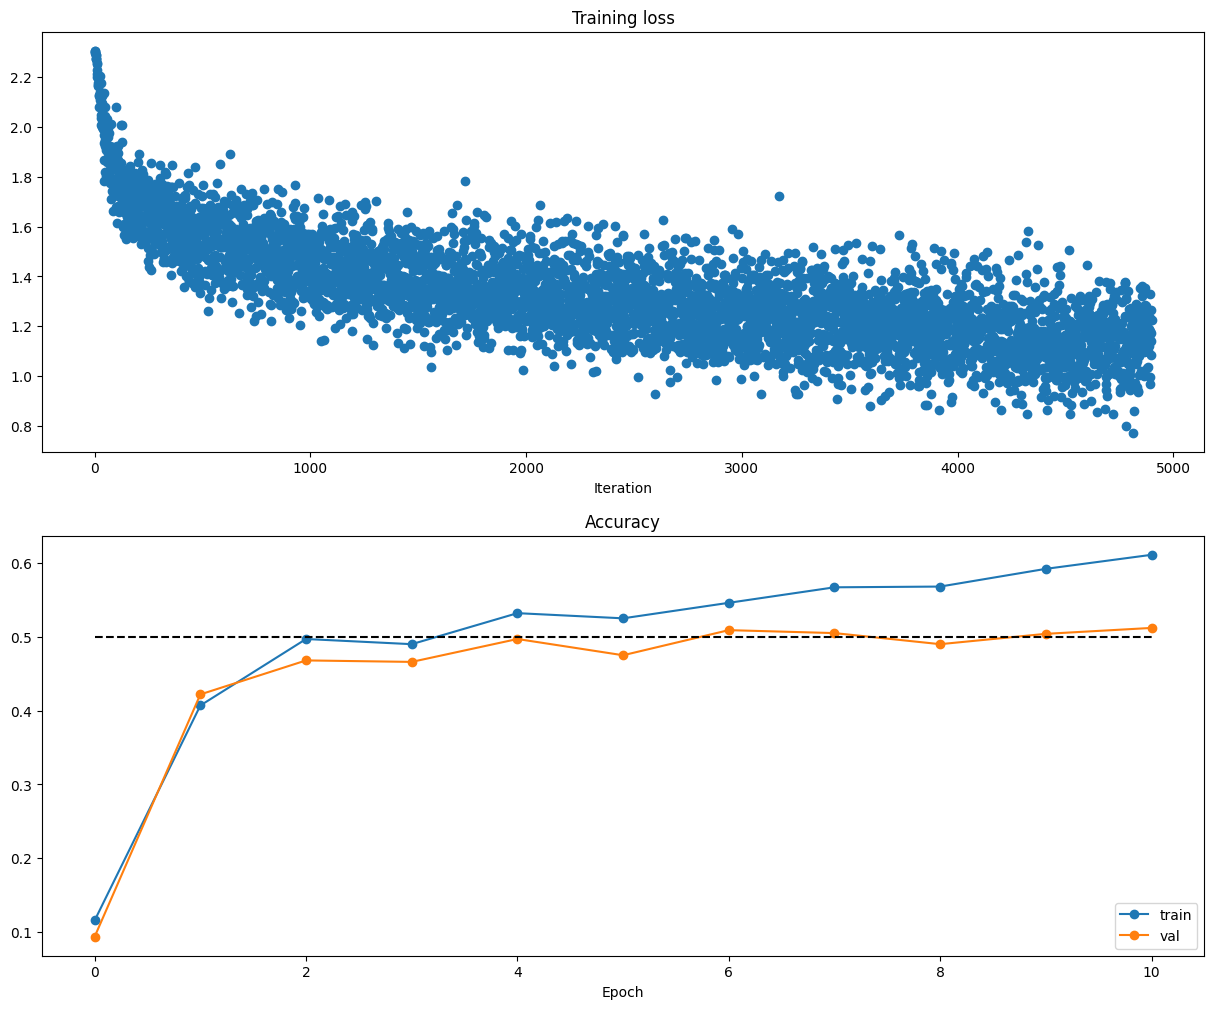

In [18]:
plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

**Выводы.** Двухслойная сеть (100 нейронов в скрытом слое, SGD, learning_rate=1e-3, lr_decay=0.95, 10 эпох) достигла accuracy **0.512** на валидации, то есть требование в 50% выполнено. На графиках loss плавно снижается, а accuracy на train и val растут почти одинаково, так что сильного переобучения нет.

Теперь реализуйте полносвязную сеть с произвольным числом скрытых слоев. Ознакомьтесь с классом FullyConnectedNet. Реализуйте инициализацию, прямой и обратный проходы.

Класс `FullyConnectedNet` сразу написан со всеми опциями: батч-нормализация (`normalization='batchnorm'`)
и dropout (`dropout < 1`). Слои `batchnorm_*` и `dropout_*` реализованы в соответствующих разделах ниже,
а без этих опций сеть их не вызывает.

In [19]:
class FullyConnectedNet(object):
    """
    Полносвязная сеть с произвольным числом скрытых слоёв:

    {affine - [batch norm] - relu - [dropout]} x (L - 1) - affine - softmax
    """

    def __init__(self, hidden_dims, input_dim=3 * 32 * 32, num_classes=10,
                 dropout=1, normalization=None, reg=0.0,
                 weight_scale=1e-2, dtype=np.float32, seed=None):
        """
        - hidden_dims: список размеров скрытых слоёв
        - dropout: вероятность СОХРАНИТЬ нейрон; 1 - без dropout
        - normalization: None или 'batchnorm'
        - reg: сила L2-регуляризации
        - weight_scale: std начальных весов
        - dtype: float64 нужен для численной проверки градиентов
        - seed: фиксирует маску dropout (для проверки градиентов)
        """
        self.normalization = normalization
        self.use_dropout = dropout != 1
        self.reg = reg
        self.num_layers = 1 + len(hidden_dims)
        self.dtype = dtype
        self.params = {}

        # размеры слоёв: вход -> скрытые -> классы
        dims = [input_dim] + list(hidden_dims) + [num_classes]
        for i in range(1, self.num_layers + 1):
            self.params['W%d' % i] = weight_scale * np.random.randn(dims[i - 1], dims[i])
            self.params['b%d' % i] = np.zeros(dims[i])
            # у скрытых слоёв с батч-нормализацией есть ещё gamma и beta
            if self.normalization == 'batchnorm' and i < self.num_layers:
                self.params['gamma%d' % i] = np.ones(dims[i])
                self.params['beta%d' % i] = np.zeros(dims[i])

        # общий словарь параметров для всех dropout-слоёв
        self.dropout_param = {}
        if self.use_dropout:
            self.dropout_param = {'mode': 'train', 'p': dropout}
            if seed is not None:
                self.dropout_param['seed'] = seed

        # у каждого слоя батч-нормализации свой словарь (running_mean / running_var)
        self.bn_params = []
        if self.normalization == 'batchnorm':
            self.bn_params = [{'mode': 'train'} for i in range(self.num_layers - 1)]

        for k, v in self.params.items():
            self.params[k] = v.astype(dtype)

    def loss(self, X, y=None):
        X = X.astype(self.dtype)
        mode = 'test' if y is None else 'train'

        # dropout и batchnorm ведут себя по-разному при обучении и на тесте
        if self.use_dropout:
            self.dropout_param['mode'] = mode
        if self.normalization == 'batchnorm':
            for bn_param in self.bn_params:
                bn_param['mode'] = mode

        # прямой проход по скрытым слоям, кэши сохраняем для обратного прохода
        caches = {}
        out = X
        for i in range(1, self.num_layers):
            W, b = self.params['W%d' % i], self.params['b%d' % i]
            out, caches['affine%d' % i] = affine_forward(out, W, b)
            if self.normalization == 'batchnorm':
                gamma, beta = self.params['gamma%d' % i], self.params['beta%d' % i]
                out, caches['bn%d' % i] = batchnorm_forward(out, gamma, beta,
                                                            self.bn_params[i - 1])
            out, caches['relu%d' % i] = relu_forward(out)
            if self.use_dropout:
                out, caches['dropout%d' % i] = dropout_forward(out, self.dropout_param)

        # последний слой - без активации
        L = self.num_layers
        scores, caches['affine%d' % L] = affine_forward(out, self.params['W%d' % L],
                                                        self.params['b%d' % L])

        if mode == 'test':
            return scores

        loss, grads = 0.0, {}
        loss, dout = softmax_loss(scores, y)
        # L2 только по весам W (gamma/beta и смещения не регуляризуем)
        for i in range(1, L + 1):
            W = self.params['W%d' % i]
            loss += 0.5 * self.reg * np.sum(W * W)

        # обратный проход: идём от последнего слоя к первому
        dout, grads['W%d' % L], grads['b%d' % L] = affine_backward(dout, caches['affine%d' % L])
        for i in range(L - 1, 0, -1):
            if self.use_dropout:
                dout = dropout_backward(dout, caches['dropout%d' % i])
            dout = relu_backward(dout, caches['relu%d' % i])
            if self.normalization == 'batchnorm':
                dout, grads['gamma%d' % i], grads['beta%d' % i] = \
                    batchnorm_backward(dout, caches['bn%d' % i])
            dout, grads['W%d' % i], grads['b%d' % i] = affine_backward(dout, caches['affine%d' % i])

        for i in range(1, L + 1):
            grads['W%d' % i] += self.reg * self.params['W%d' % i]

        return loss, grads

In [ ]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)
  
  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Running check with reg =  0
Initial loss:  2.3004790897684924
W1 relative error: 1.48e-07
W2 relative error: 2.21e-05
W3 relative error: 3.53e-07
b1 relative error: 5.38e-09
b2 relative error: 2.09e-09
b3 relative error: 5.80e-11
Running check with reg =  3.14
Initial loss:  7.052114776533016
W1 relative error: 3.90e-09
W2 relative error: 6.87e-08
W3 relative error: 2.13e-08
b1 relative error: 1.48e-08
b2 relative error: 1.72e-09
b3 relative error: 1.57e-10


Попробуйте добиться эффекта переобучения на небольшом наборе изображений (например, 50). Используйте трехслойную сеть со 100 нейронами на каждом скрытом слое. Попробуйте переобучить сеть, достигнув 100 % accuracy за 20 эпох. Для этого поэкспериментируйте с параметрами weight_scale и learning_rate. 

(Iteration 1 / 40) loss: 2.301506
(Epoch 0 / 20) train acc: 0.280000; val_acc: 0.099000
(Epoch 1 / 20) train acc: 0.360000; val_acc: 0.107000
(Epoch 2 / 20) train acc: 0.460000; val_acc: 0.165000
(Epoch 3 / 20) train acc: 0.540000; val_acc: 0.143000
(Epoch 4 / 20) train acc: 0.600000; val_acc: 0.176000
(Epoch 5 / 20) train acc: 0.700000; val_acc: 0.176000
(Iteration 11 / 40) loss: 0.867416
(Epoch 6 / 20) train acc: 0.620000; val_acc: 0.152000
(Epoch 7 / 20) train acc: 0.760000; val_acc: 0.157000
(Epoch 8 / 20) train acc: 0.860000; val_acc: 0.172000
(Epoch 9 / 20) train acc: 0.880000; val_acc: 0.161000
(Epoch 10 / 20) train acc: 0.960000; val_acc: 0.159000
(Iteration 21 / 40) loss: 0.573227
(Epoch 11 / 20) train acc: 0.940000; val_acc: 0.158000
(Epoch 12 / 20) train acc: 0.920000; val_acc: 0.173000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.173000
(Epoch 14 / 20) train acc: 0.980000; val_acc: 0.171000
(Epoch 15 / 20) train acc: 0.920000; val_acc: 0.150000
(Iteration 31 / 40) loss: 

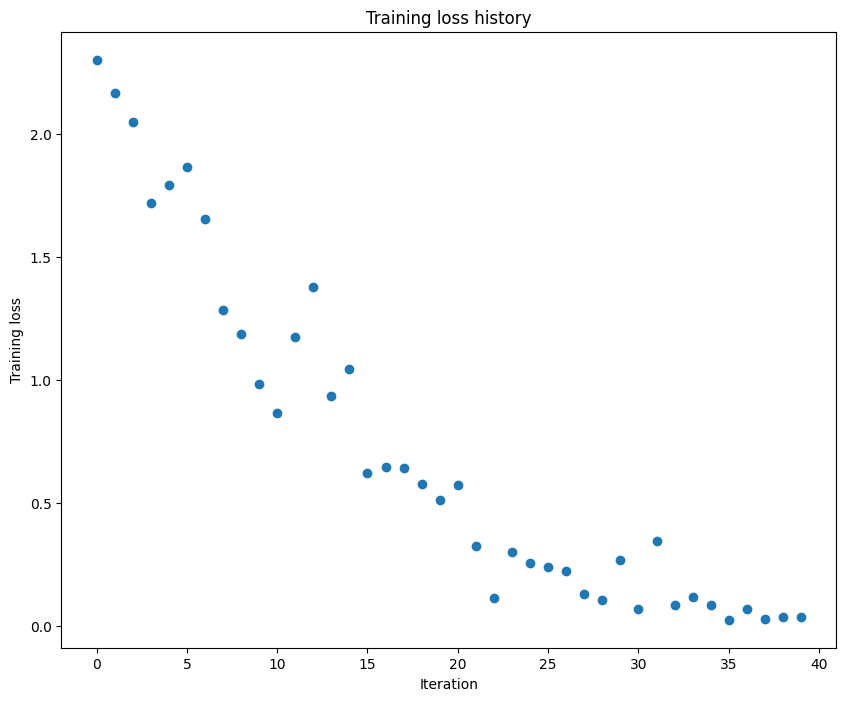

Final train accuracy:  1.0


In [ ]:
np.random.seed(231)
num_train = 50
small_data = \
{
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 1e-2
learning_rate = 1e-2
model = FullyConnectedNet([100, 100],
              weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()
print('Final train accuracy: ', solver.train_acc_history[-1])

Повторите эксперимент, описанный выше, для пятислойной сети.

(Iteration 1 / 40) loss: 5.357758
(Epoch 0 / 20) train acc: 0.160000; val_acc: 0.082000
(Epoch 1 / 20) train acc: 0.200000; val_acc: 0.125000
(Epoch 2 / 20) train acc: 0.540000; val_acc: 0.121000
(Epoch 3 / 20) train acc: 0.740000; val_acc: 0.134000
(Epoch 4 / 20) train acc: 0.800000; val_acc: 0.134000
(Epoch 5 / 20) train acc: 0.860000; val_acc: 0.121000
(Iteration 11 / 40) loss: 0.869825
(Epoch 6 / 20) train acc: 0.940000; val_acc: 0.127000
(Epoch 7 / 20) train acc: 0.940000; val_acc: 0.128000
(Epoch 8 / 20) train acc: 0.960000; val_acc: 0.134000
(Epoch 9 / 20) train acc: 0.980000; val_acc: 0.124000
(Epoch 10 / 20) train acc: 0.980000; val_acc: 0.131000
(Iteration 21 / 40) loss: 0.109635
(Epoch 11 / 20) train acc: 1.000000; val_acc: 0.137000
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.136000
(Epoch 13 / 20) train acc: 1.000000; val_acc: 0.136000
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.129000
(Epoch 15 / 20) train acc: 1.000000; val_acc: 0.124000
(Iteration 31 / 40) loss: 

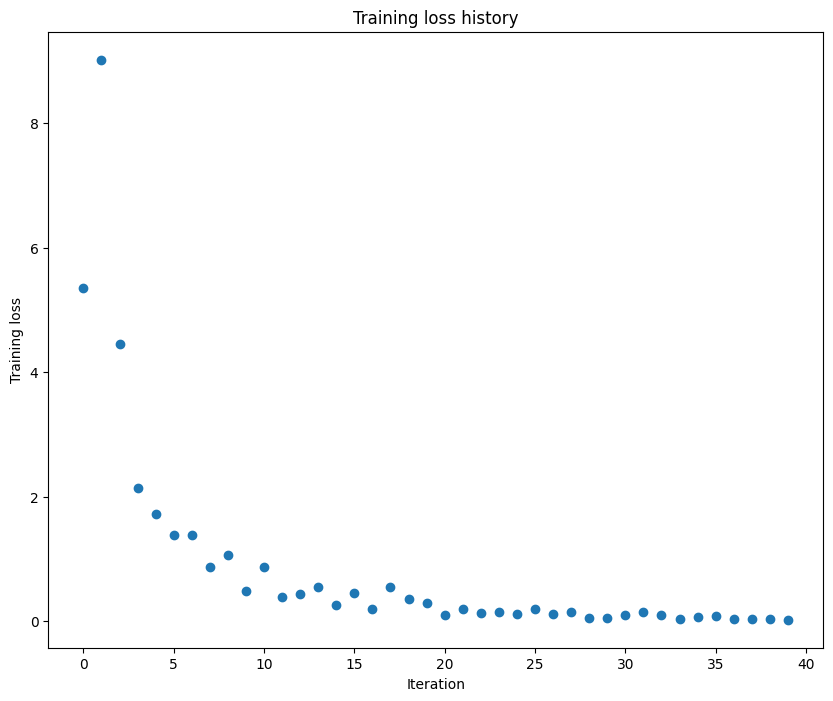

Final train accuracy:  1.0


In [22]:
np.random.seed(231)
num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

learning_rate = 1e-2
weight_scale = 5e-2
model = FullyConnectedNet([100, 100, 100, 100],
                weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()
print('Final train accuracy: ', solver.train_acc_history[-1])

Сделайте выводы по проведенному эксперименту. 

**Выводы.** - Трёхслойная сеть (weight_scale=1e-2, learning_rate=1e-2) за 20 эпох запоминает все 50 примеров: train accuracy = **1.0**.
- Пятислойная сеть (weight_scale=5e-2, learning_rate=1e-2) тоже доходит до train accuracy = **1.0**, но гораздо чувствительнее к масштабу инициализации. При weight_scale=1e-5 (значение из шаблона) сигнал затухает уже через несколько слоёв, градиенты почти нулевые, и сеть не обучается. При слишком большом шаге обучение становится нестабильным.
- Чем глубже сеть, тем аккуратнее нужно подбирать weight_scale и learning_rate. На валидации обе сети показывают низкое качество, что ожидаемо: 50 картинок слишком мало, и сеть просто их запоминает.

Ранее обновление весов проходило по правилу SGD. Теперь попробуйте реализовать стохастический градиентный спуск с импульсом (SGD+momentum). http://cs231n.github.io/neural-networks-3/#sgd Реализуйте sgd_momentum и запустите проверку. 

In [23]:
def sgd_momentum(w, dw, config=None):
    """
    SGD с импульсом:
        v = momentum * v - lr * dw
        w = w + v
    """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-2)
    config.setdefault('momentum', 0.9)
    v = config.get('velocity', np.zeros_like(w))

    v = config['momentum'] * v - config['learning_rate'] * dw
    next_w = w + v

    config['velocity'] = v
    return next_w, config

In [ ]:

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-3, 'velocity': v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray
(
[
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]
]
)
expected_velocity = np.asarray
(
  [
    [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
    [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
    [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
    [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]
  ]
  )

print('next_w error: ', rel_error(next_w, expected_next_w))
print('velocity error: ', rel_error(expected_velocity, config['velocity']))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


Сравните результаты обучения шестислойной сети, обученной классическим градиентным спуском и адаптивным алгоритмом с импульсом. Какой алгоритм сходится быстрее.

running with  sgd
(Iteration 1 / 200) loss: 2.870056
(Epoch 0 / 5) train acc: 0.113000; val_acc: 0.104000
(Iteration 11 / 200) loss: 2.260219
(Iteration 21 / 200) loss: 2.164585
(Iteration 31 / 200) loss: 2.164986
(Epoch 1 / 5) train acc: 0.246000; val_acc: 0.198000
(Iteration 41 / 200) loss: 2.171974
(Iteration 51 / 200) loss: 2.034330
(Iteration 61 / 200) loss: 2.049563
(Iteration 71 / 200) loss: 1.996434
(Epoch 2 / 5) train acc: 0.289000; val_acc: 0.233000
(Iteration 81 / 200) loss: 2.008327
(Iteration 91 / 200) loss: 2.048557
(Iteration 101 / 200) loss: 1.974882
(Iteration 111 / 200) loss: 1.895680
(Epoch 3 / 5) train acc: 0.313000; val_acc: 0.281000
(Iteration 121 / 200) loss: 1.941965
(Iteration 131 / 200) loss: 1.940493
(Iteration 141 / 200) loss: 1.865231
(Iteration 151 / 200) loss: 1.966755
(Epoch 4 / 5) train acc: 0.354000; val_acc: 0.310000
(Iteration 161 / 200) loss: 1.805889
(Iteration 171 / 200) loss: 1.879388
(Iteration 181 / 200) loss: 1.769853
(Iteration 191 / 200) los

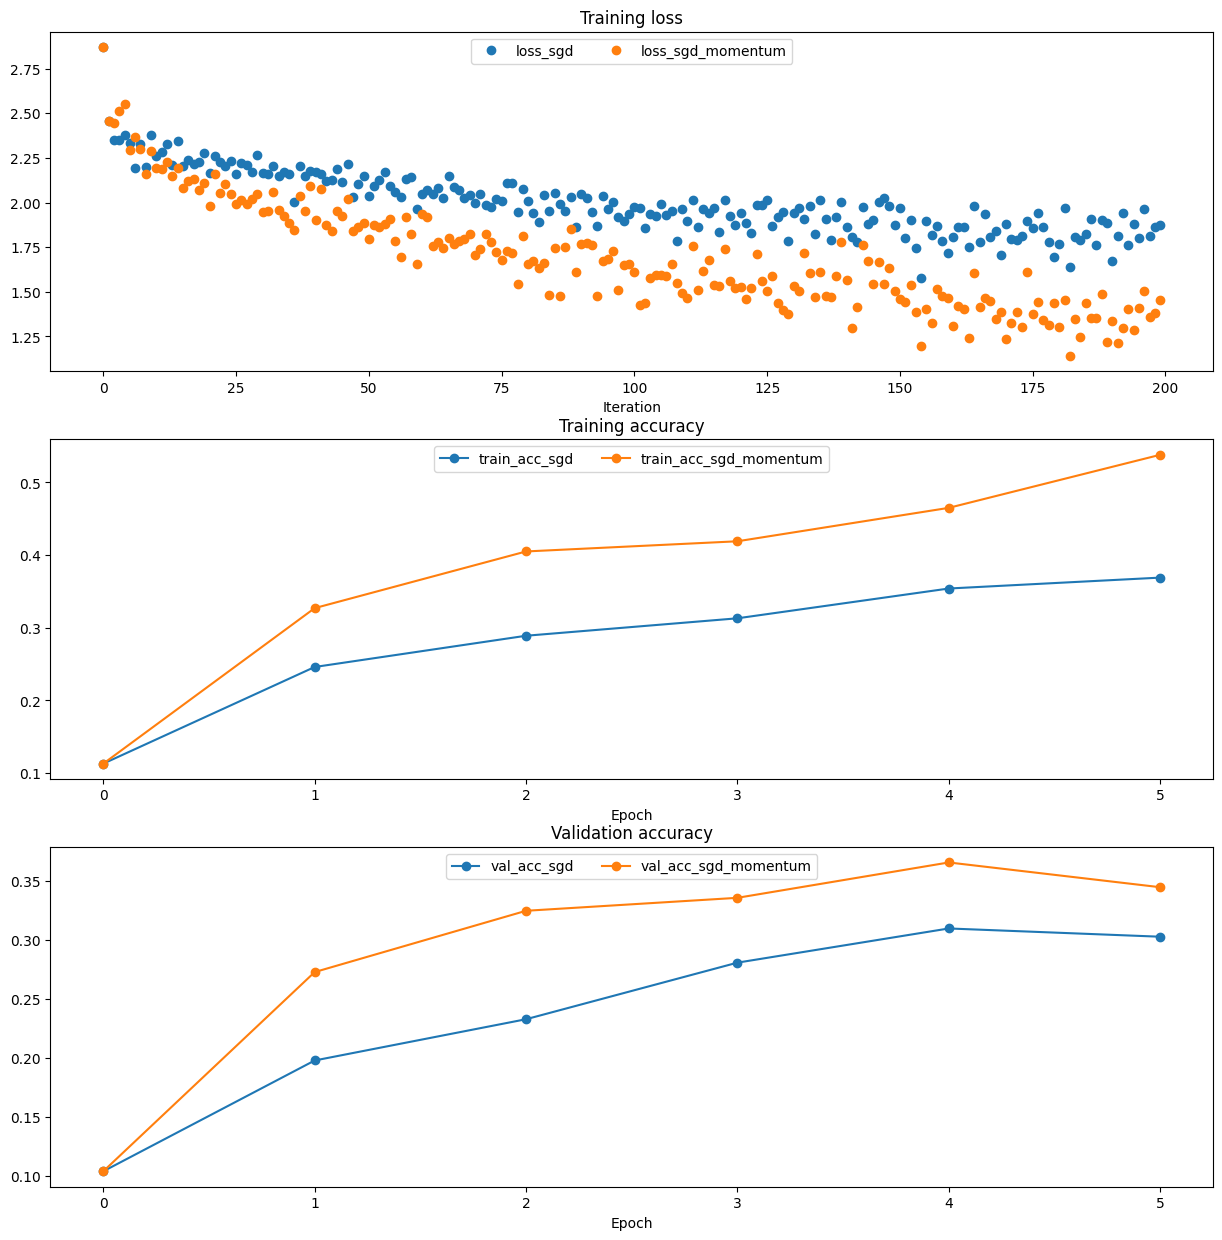

In [25]:
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
  print('running with ', update_rule)
  np.random.seed(231)
  model = FullyConnectedNet([100, 100, 100, 100, 100], weight_scale=5e-2)

  solver = Solver(model, small_data,
                  num_epochs=5, batch_size=100,
                  update_rule=update_rule,
                  optim_config={
                    'learning_rate': 5e-3,
                  },
                  verbose=True)
  solvers[update_rule] = solver
  solver.train()
  print()

plt.subplot(3, 1, 1)
plt.title('Training loss')
plt.xlabel('Iteration')

plt.subplot(3, 1, 2)
plt.title('Training accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 3)
plt.title('Validation accuracy')
plt.xlabel('Epoch')

for update_rule, solver in solvers.items():
  plt.subplot(3, 1, 1)
  plt.plot(solver.loss_history, 'o', label="loss_%s" % update_rule)
  
  plt.subplot(3, 1, 2)
  plt.plot(solver.train_acc_history, '-o', label="train_acc_%s" % update_rule)

  plt.subplot(3, 1, 3)
  plt.plot(solver.val_acc_history, '-o', label="val_acc_%s" % update_rule)
  
for i in [1, 2, 3]:
  plt.subplot(3, 1, i)
  plt.legend(loc='upper center', ncol=4)
plt.gcf().set_size_inches(15, 15)
plt.show()

**Выводы.** SGD с импульсом сходится заметно быстрее обычного SGD: loss падает быстрее (≈1.3-1.5 против ≈1.8-1.9 к концу 5-й эпохи), accuracy на train за 5 эпох **0.54** против **0.37**, лучшая accuracy на val **0.366** против **0.310**. Импульс накапливает скорость в устойчивом направлении градиента и гасит колебания, поэтому шаги получаются эффективнее.

Реализуйте алгоритмы RMSProp [1] and Adam [2] с коррекцией смещения  - методы rmsprop и adam . 


[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [26]:
def rmsprop(w, dw, config=None):
    """
    RMSProp: скользящее среднее квадратов градиента задаёт свой шаг для каждого веса
        cache = decay * cache + (1 - decay) * dw^2
        w = w - lr * dw / (sqrt(cache) + eps)
    """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-2)
    config.setdefault('decay_rate', 0.99)
    config.setdefault('epsilon', 1e-8)
    config.setdefault('cache', np.zeros_like(w))

    decay = config['decay_rate']
    config['cache'] = decay * config['cache'] + (1 - decay) * dw ** 2
    next_w = w - config['learning_rate'] * dw / (np.sqrt(config['cache']) + config['epsilon'])

    return next_w, config

In [ ]:
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


In [28]:
def adam(w, dw, config=None):
    """
    Adam: скользящие средние градиента (m) и его квадрата (v) с коррекцией смещения
        t = t + 1
        m = beta1 * m + (1 - beta1) * dw
        v = beta2 * v + (1 - beta2) * dw^2
        m_hat = m / (1 - beta1^t),  v_hat = v / (1 - beta2^t)
        w = w - lr * m_hat / (sqrt(v_hat) + eps)
    """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-3)
    config.setdefault('beta1', 0.9)
    config.setdefault('beta2', 0.999)
    config.setdefault('epsilon', 1e-8)
    config.setdefault('m', np.zeros_like(w))
    config.setdefault('v', np.zeros_like(w))
    config.setdefault('t', 0)

    beta1, beta2 = config['beta1'], config['beta2']
    config['t'] += 1   # t увеличиваем до использования
    config['m'] = beta1 * config['m'] + (1 - beta1) * dw
    config['v'] = beta2 * config['v'] + (1 - beta2) * dw ** 2
    m_hat = config['m'] / (1 - beta1 ** config['t'])
    v_hat = config['v'] / (1 - beta2 ** config['t'])
    next_w = w - config['learning_rate'] * m_hat / (np.sqrt(v_hat) + config['epsilon'])

    return next_w, config

In [ ]:
# Test Adam implementation

N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  1.1395691798535431e-07
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Обучите пару глубоких сетей с испольованием RMSProp и Adam алгоритмов обновления весов и сравните результаты обучения.

running with  adam
(Iteration 1 / 200) loss: 2.870056
(Epoch 0 / 5) train acc: 0.144000; val_acc: 0.119000
(Iteration 11 / 200) loss: 2.087330
(Iteration 21 / 200) loss: 1.830715
(Iteration 31 / 200) loss: 1.815505
(Epoch 1 / 5) train acc: 0.349000; val_acc: 0.320000
(Iteration 41 / 200) loss: 1.856428
(Iteration 51 / 200) loss: 1.689808
(Iteration 61 / 200) loss: 1.798559
(Iteration 71 / 200) loss: 1.390801
(Epoch 2 / 5) train acc: 0.443000; val_acc: 0.348000
(Iteration 81 / 200) loss: 1.632947
(Iteration 91 / 200) loss: 1.562765
(Iteration 101 / 200) loss: 1.359093
(Iteration 111 / 200) loss: 1.381037
(Epoch 3 / 5) train acc: 0.457000; val_acc: 0.356000
(Iteration 121 / 200) loss: 1.345759
(Iteration 131 / 200) loss: 1.432111
(Iteration 141 / 200) loss: 1.401747
(Iteration 151 / 200) loss: 1.222421
(Epoch 4 / 5) train acc: 0.551000; val_acc: 0.355000
(Iteration 161 / 200) loss: 1.292665
(Iteration 171 / 200) loss: 1.062366
(Iteration 181 / 200) loss: 1.245898
(Iteration 191 / 200) lo

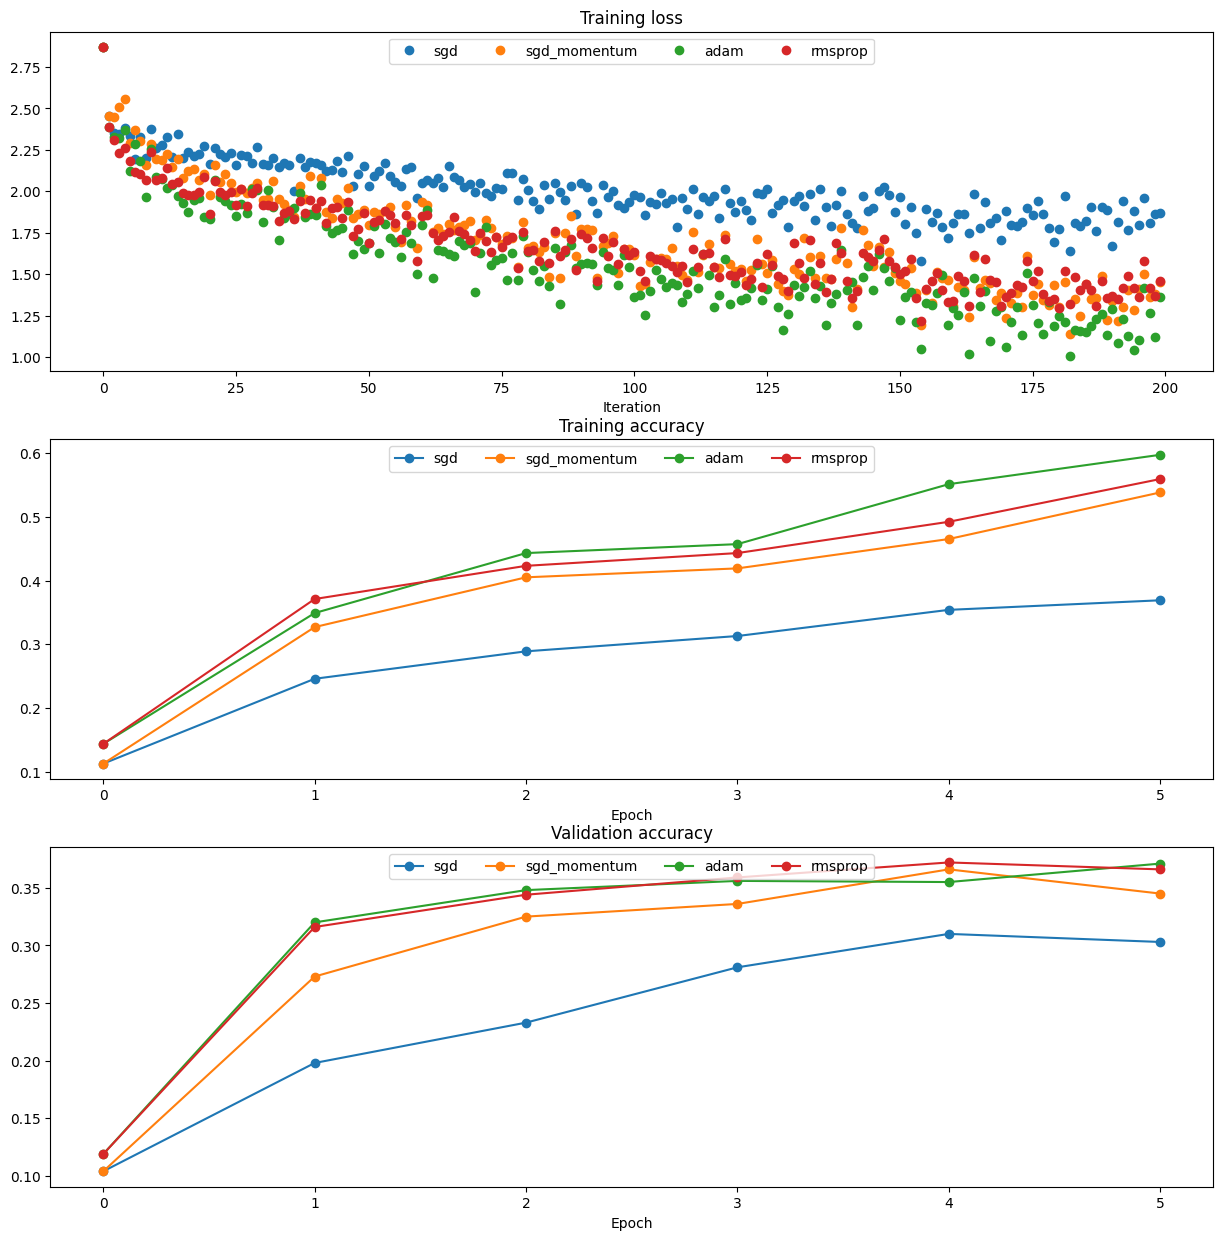

sgd           final train acc: 0.369  best val acc: 0.310
sgd_momentum  final train acc: 0.538  best val acc: 0.366
adam          final train acc: 0.597  best val acc: 0.371
rmsprop       final train acc: 0.559  best val acc: 0.372


In [30]:
# та же шестислойная сеть и те же данные, что и для sgd / sgd_momentum выше
learning_rates = {'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['adam', 'rmsprop']:
    print('running with ', update_rule)
    np.random.seed(231)
    model = FullyConnectedNet([100, 100, 100, 100, 100], weight_scale=5e-2)

    solver = Solver(model, small_data,
                    num_epochs=5, batch_size=100,
                    update_rule=update_rule,
                    optim_config={'learning_rate': learning_rates[update_rule]},
                    verbose=True)
    solvers[update_rule] = solver
    solver.train()
    print()

plt.subplot(3, 1, 1)
plt.title('Training loss')
plt.xlabel('Iteration')

plt.subplot(3, 1, 2)
plt.title('Training accuracy')
plt.xlabel('Epoch')

plt.subplot(3, 1, 3)
plt.title('Validation accuracy')
plt.xlabel('Epoch')

for update_rule, solver in solvers.items():
    plt.subplot(3, 1, 1)
    plt.plot(solver.loss_history, 'o', label=update_rule)

    plt.subplot(3, 1, 2)
    plt.plot(solver.train_acc_history, '-o', label=update_rule)

    plt.subplot(3, 1, 3)
    plt.plot(solver.val_acc_history, '-o', label=update_rule)

for i in [1, 2, 3]:
    plt.subplot(3, 1, i)
    plt.legend(loc='upper center', ncol=4)
plt.gcf().set_size_inches(15, 15)
plt.show()

for update_rule, solver in solvers.items():
    print('%-13s final train acc: %.3f  best val acc: %.3f'
          % (update_rule, solver.train_acc_history[-1], solver.best_val_acc))

**Выводы.** Оба адаптивных метода обгоняют обычный SGD. За 5 эпох Adam (lr=1e-3) даёт train accuracy **0.60** и val **0.371**, RMSProp (lr=1e-4) даёт train **0.56** и val **0.372**, SGD+momentum даёт 0.54 и 0.366, обычный SGD даёт 0.37 и 0.310. Быстрее всего loss снижается у Adam: он сочетает импульс (скользящее среднее градиента) и свой шаг для каждого веса (как RMSProp).

# Нормализация по мини-батчам

Идея нормализации по мини-батчам предложена в работе [1]

[1] Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift", ICML 2015.

Реализуйте прямой проход для слоя батч-нормализации - функция batchnorm_forward. Проверьте свою реализацию, запустив следующий код:

In [31]:
def batchnorm_forward(x, gamma, beta, bn_param):
    """
    Прямой проход батч-нормализации.
    x: (N, D), gamma, beta: (D,)
    bn_param: mode ('train' / 'test'), eps, momentum, running_mean, running_var

    При обучении нормируем по статистикам мини-батча и обновляем скользящие средние:
        running_mean = momentum * running_mean + (1 - momentum) * sample_mean
        running_var  = momentum * running_var  + (1 - momentum) * sample_var
    На тесте нормируем по running_mean / running_var.
    """
    mode = bn_param['mode']
    eps = bn_param.get('eps', 1e-5)
    momentum = bn_param.get('momentum', 0.9)

    N, D = x.shape
    running_mean = bn_param.get('running_mean', np.zeros(D, dtype=x.dtype))
    running_var = bn_param.get('running_var', np.zeros(D, dtype=x.dtype))

    out, cache = None, None
    if mode == 'train':
        sample_mean = x.mean(axis=0)
        sample_var = x.var(axis=0)
        std = np.sqrt(sample_var + eps)
        x_hat = (x - sample_mean) / std         # нулевое среднее, единичная дисперсия
        out = gamma * x_hat + beta              # масштаб и сдвиг

        running_mean = momentum * running_mean + (1 - momentum) * sample_mean
        running_var = momentum * running_var + (1 - momentum) * sample_var

        cache = (x_hat, gamma, std)
    elif mode == 'test':
        x_hat = (x - running_mean) / np.sqrt(running_var + eps)
        out = gamma * x_hat + beta
    else:
        raise ValueError('Invalid forward batchnorm mode "%s"' % mode)

    bn_param['running_mean'] = running_mean
    bn_param['running_var'] = running_var

    return out, cache

In [ ]:
# Simulate the forward pass for a two-layer network
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print_mean_std(a,axis=0)

gamma = np.ones((D3,))
beta = np.zeros((D3,))

print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])

print('After batch normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm,axis=0)

Before batch normalization:
  means:  [ -2.3814598  -13.18038246   1.91780462]
  stds:   [27.18502186 34.21455511 37.68611762]

After batch normalization (gamma=1, beta=0)
  means:  [ 5.32907052e-17  3.44169138e-17 -8.18789481e-18]
  stds:   [0.99999999 1.         1.        ]

After batch normalization (gamma= [1. 2. 3.] , beta= [11. 12. 13.] )
  means:  [11. 12. 13.]
  stds:   [0.99999999 1.99999999 2.99999999]



In [ ]:
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)

for t in range(50):
  X = np.random.randn(N, D1)
  a = np.maximum(0, X.dot(W1)).dot(W2)
  batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

print('After batch normalization (test-time):')
print_mean_std(a_norm,axis=0)

After batch normalization (test-time):
  means:  [-0.03927354 -0.04349152 -0.10452688]
  stds:   [1.01531428 1.01238373 0.97819988]



Реализуйте обратный проход в функции batchnorm_backward.

In [34]:
def batchnorm_backward(dout, cache):
    """
    Обратный проход батч-нормализации.
    Формула для dx получена из графа вычислений
    x -> (mean, var) -> x_hat -> gamma * x_hat + beta после упрощения.
    """
    x_hat, gamma, std = cache
    N = dout.shape[0]

    dbeta = np.sum(dout, axis=0)
    dgamma = np.sum(dout * x_hat, axis=0)

    dx_hat = dout * gamma
    dx = (N * dx_hat - np.sum(dx_hat, axis=0)
          - x_hat * np.sum(dx_hat * x_hat, axis=0)) / (N * std)

    return dx, dgamma, dbeta

In [ ]:
# Gradient check batchnorm backward pass
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)

print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.7029226384366253e-09
dgamma error:  7.420414216247087e-13
dbeta error:  2.8795057655839487e-12


Измените реализацию класса FullyConnectedNet, добавив батч-нормализацию. 
Если флаг normalization == "batchnorm", то вам необходимо вставить слой батч-нормализации перед каждым слоем активации ReLU, кроме выхода сети. 

Поддержка батч-нормализации уже добавлена в класс `FullyConnectedNet` выше (параметр `normalization`).

In [ ]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
  print('Running check with reg = ', reg)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            reg=reg, weight_scale=5e-2, dtype=np.float64,
                            normalization='batchnorm')

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  if reg == 0: print()

Running check with reg =  0
Initial loss:  2.2611955101340957
W1 relative error: 1.10e-04
W2 relative error: 2.85e-06
W3 relative error: 4.05e-10
b1 relative error: 2.22e-07
b2 relative error: 2.22e-08
b3 relative error: 1.01e-10
beta1 relative error: 7.33e-09
beta2 relative error: 1.89e-09
gamma1 relative error: 6.96e-09
gamma2 relative error: 1.96e-09

Running check with reg =  3.14
Initial loss:  6.996533220108303
W1 relative error: 1.98e-06
W2 relative error: 2.28e-06
W3 relative error: 1.11e-08
b1 relative error: 1.38e-08
b2 relative error: 7.99e-07
b3 relative error: 1.73e-10
beta1 relative error: 6.65e-09
beta2 relative error: 3.48e-09
gamma1 relative error: 8.80e-09
gamma2 relative error: 5.28e-09


Обучите 6-ти слойную сеть на наборе из 1000 изображений с батч-нормализацией и без нее

In [ ]:
np.random.seed(231)
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

print('Solver with batch norm:')
bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True,print_every=20)
bn_solver.train()

print('\nSolver without batch norm:')
solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

Solver with batch norm:
(Iteration 1 / 200) loss: 2.340974
(Epoch 0 / 10) train acc: 0.107000; val_acc: 0.115000
(Epoch 1 / 10) train acc: 0.314000; val_acc: 0.267000
(Iteration 21 / 200) loss: 2.039365
(Epoch 2 / 10) train acc: 0.386000; val_acc: 0.279000
(Iteration 41 / 200) loss: 2.041103
(Epoch 3 / 10) train acc: 0.491000; val_acc: 0.309000
(Iteration 61 / 200) loss: 1.753902
(Epoch 4 / 10) train acc: 0.530000; val_acc: 0.307000
(Iteration 81 / 200) loss: 1.246584
(Epoch 5 / 10) train acc: 0.572000; val_acc: 0.314000
(Iteration 101 / 200) loss: 1.320589
(Epoch 6 / 10) train acc: 0.633000; val_acc: 0.339000
(Iteration 121 / 200) loss: 1.159472
(Epoch 7 / 10) train acc: 0.687000; val_acc: 0.325000
(Iteration 141 / 200) loss: 1.156477
(Epoch 8 / 10) train acc: 0.769000; val_acc: 0.333000
(Iteration 161 / 200) loss: 0.630540
(Epoch 9 / 10) train acc: 0.801000; val_acc: 0.343000
(Iteration 181 / 200) loss: 0.862818
(Epoch 10 / 10) train acc: 0.789000; val_acc: 0.335000

Solver without b

Визуализируйте процесс обучения для двух сетей. Увеличилась ли скорость сходимости в случае с батч-нормализацией? Сделайте выводы. 

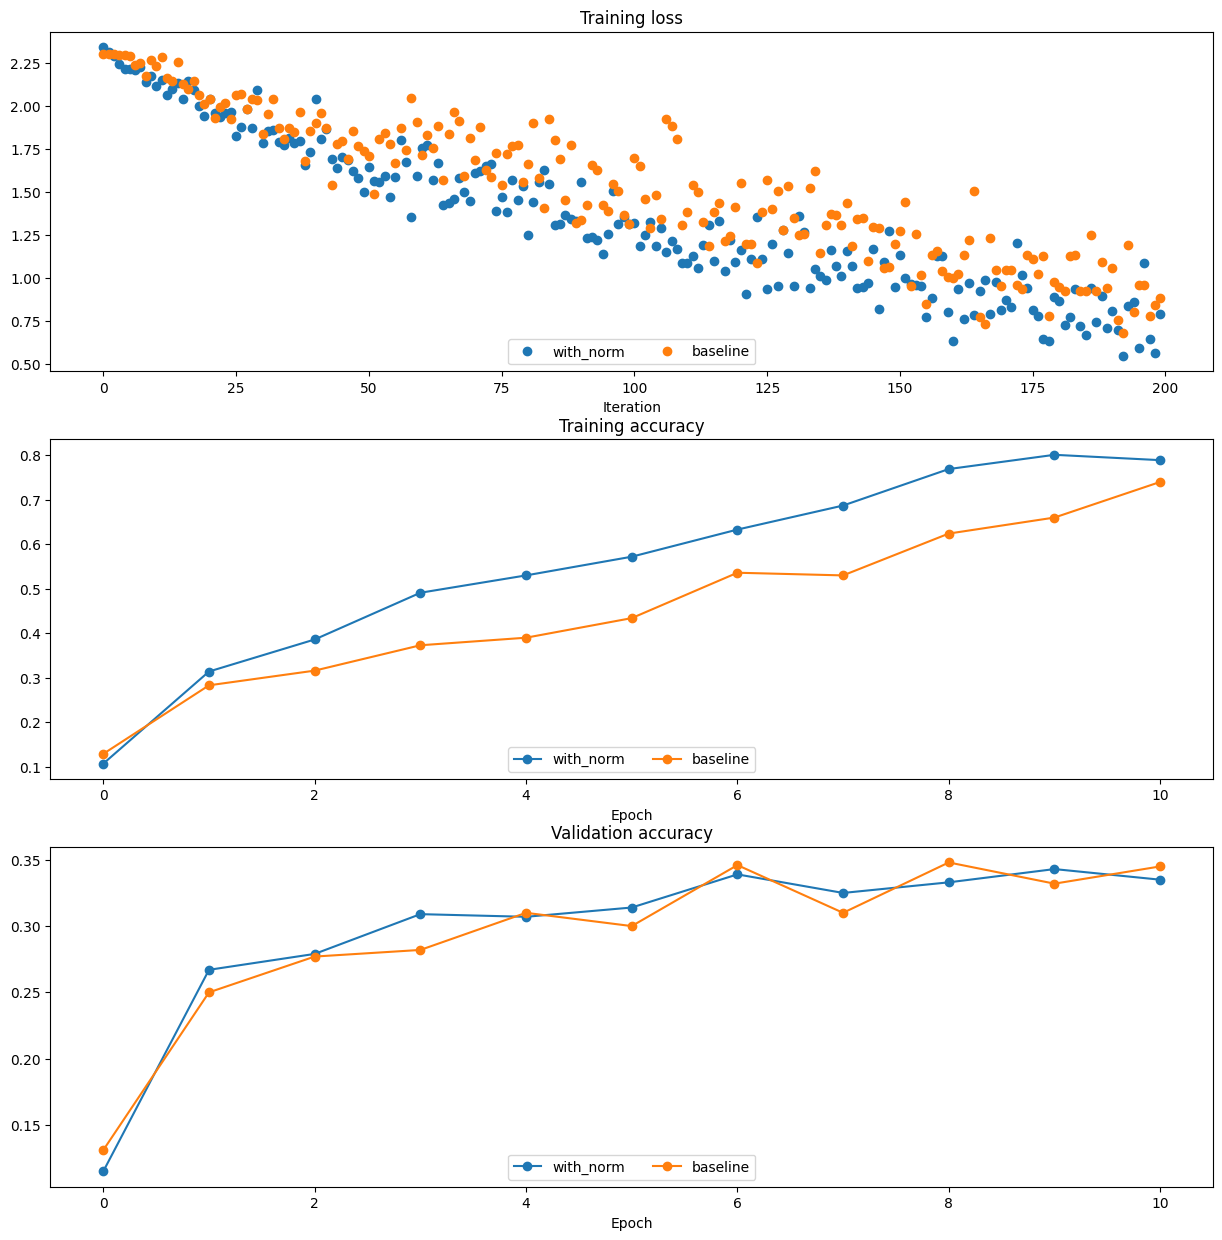

In [38]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn, bl_marker='.', bn_marker='.', labels=None):
    """utility function for plotting training history"""
    plt.title(title)
    plt.xlabel(label)
    bn_plots = [plot_fn(bn_solver) for bn_solver in bn_solvers]
    bl_plot = plot_fn(baseline)
    num_bn = len(bn_plots)
    for i in range(num_bn):
        label='with_norm'
        if labels is not None:
            label += str(labels[i])
        plt.plot(bn_plots[i], bn_marker, label=label)
    label='baseline'
    if labels is not None:
        label += str(labels[0])
    plt.plot(bl_plot, bl_marker, label=label)
    plt.legend(loc='lower center', ncol=num_bn+1) 

    
plt.subplot(3, 1, 1)
plot_training_history('Training loss','Iteration', solver, [bn_solver], \
                      lambda x: x.loss_history, bl_marker='o', bn_marker='o')
plt.subplot(3, 1, 2)
plot_training_history('Training accuracy','Epoch', solver, [bn_solver], \
                      lambda x: x.train_acc_history, bl_marker='-o', bn_marker='-o')
plt.subplot(3, 1, 3)
plot_training_history('Validation accuracy','Epoch', solver, [bn_solver], \
                      lambda x: x.val_acc_history, bl_marker='-o', bn_marker='-o')

plt.gcf().set_size_inches(15, 15)
plt.show()

**Выводы.** С батч-нормализацией сеть обучается быстрее: loss снижается быстрее, accuracy на train на каждой эпохе выше (0.79 против 0.74 в конце). На валидации разница небольшая (≈0.34 у обеих), потому что 1000 картинок мало и обе сети начинают переобучаться. Итог: батч-нормализация ускоряет сходимость глубокой сети, так как распределение входов каждого слоя остаётся стабильным.

Обучите 6-тислойную сеть с батч-нормализацией и без нее, используя разные размеры батча. Визуализируйте графики обучения. Сделайте выводы по результатам эксперимента. 

In [ ]:
def run_batchsize_experiments(normalization_mode):
    np.random.seed(231)

    hidden_dims = [100, 100, 100, 100, 100]
    num_train = 1000
    small_data = {
      'X_train': data['X_train'][:num_train],
      'y_train': data['y_train'][:num_train],
      'X_val': data['X_val'],
      'y_val': data['y_val'],
    }
    n_epochs=10
    weight_scale = 2e-2
    batch_sizes = [5,10,50]
    lr = 10**(-3.5)
    solver_bsize = batch_sizes[0]

    print('No normalization: batch size = ',solver_bsize)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)
    solver = Solver(model, small_data,
                    num_epochs=n_epochs, batch_size=solver_bsize,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': lr,
                    },
                    verbose=False)
    solver.train()
    
    bn_solvers = []
    for i in range(len(batch_sizes)):
        b_size=batch_sizes[i]
        print('Normalization: batch size = ',b_size)
        bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=normalization_mode)
        bn_solver = Solver(bn_model, small_data,
                        num_epochs=n_epochs, batch_size=b_size,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        verbose=False)
        bn_solver.train()
        bn_solvers.append(bn_solver)
        
    return bn_solvers, solver, batch_sizes

batch_sizes = [5,10,50]
bn_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('batchnorm')

No normalization: batch size =  5
Normalization: batch size =  5
Normalization: batch size =  10
Normalization: batch size =  50


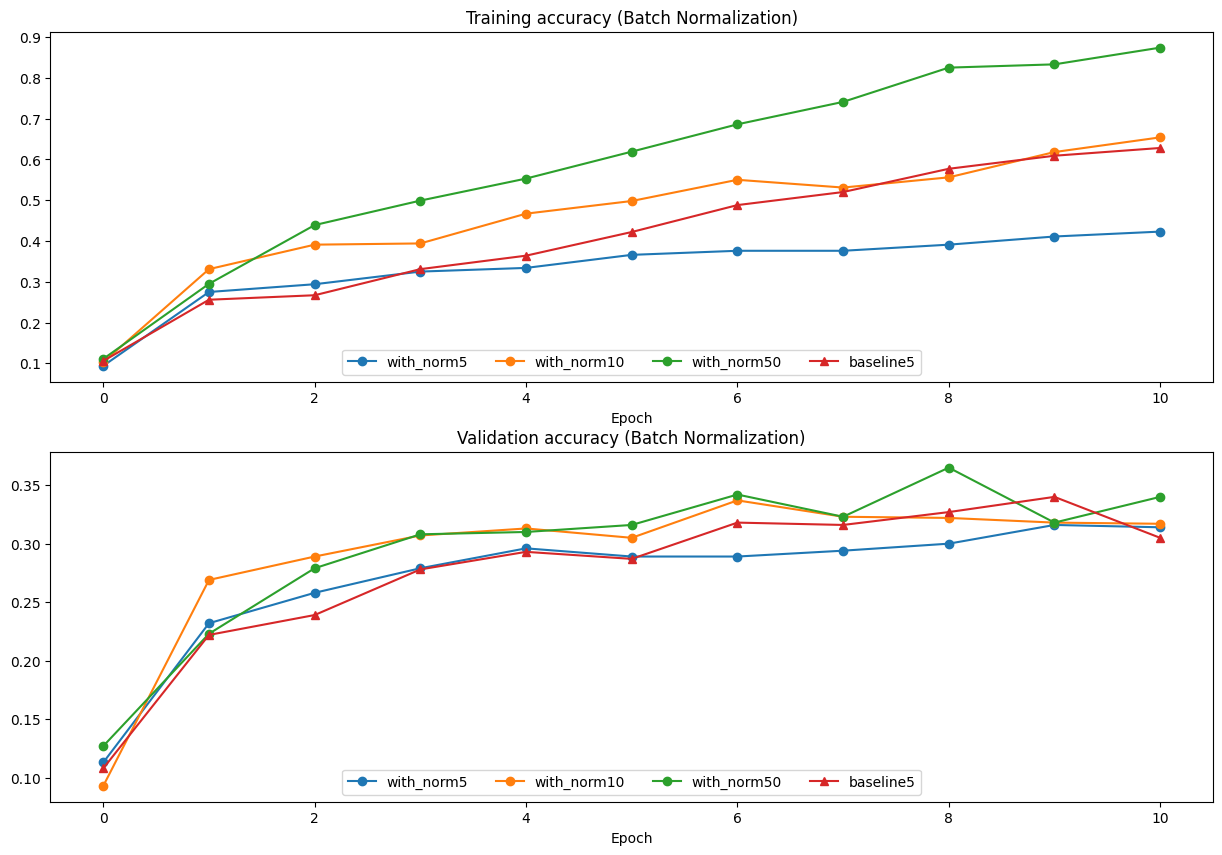

In [40]:
plt.subplot(2, 1, 1)
plot_training_history('Training accuracy (Batch Normalization)','Epoch', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Validation accuracy (Batch Normalization)','Epoch', solver_bsize, bn_solvers_bsize, \
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.show()

**Выводы.** Эффект батч-нормализации сильно зависит от размера батча. С батчем 50 сеть с BN обучается лучше всех (train ≈ 0.87, val до ≈ 0.36). С батчем 10 результат примерно как у сети без нормализации. С батчем 5 сеть с BN обучается хуже всех (train ≈ 0.42): среднее и дисперсия по 5 примерам очень шумные, и нормализация вносит больше шума, чем пользы. Батч-нормализацию стоит применять с достаточно большими батчами.

# Dropout

Реализуйте прямой проход для dropout-слоя

http://cs231n.github.io/neural-networks-2/#reg

In [41]:
def dropout_forward(x, dropout_param):
    """
    Inverted dropout.
    p - вероятность СОХРАНИТЬ нейрон. При обучении выход делится на p,
    поэтому на тесте ничего масштабировать не нужно.
    """
    p, mode = dropout_param['p'], dropout_param['mode']
    if 'seed' in dropout_param:
        np.random.seed(dropout_param['seed'])

    mask = None
    out = None

    if mode == 'train':
        mask = (np.random.rand(*x.shape) < p) / p
        out = x * mask
    elif mode == 'test':
        out = x

    cache = (dropout_param, mask)
    out = out.astype(x.dtype, copy=False)

    return out, cache

In [42]:
np.random.seed(231)
x = np.random.randn(500, 500) + 10

for p in [0.25, 0.4, 0.7]:
  out, _ = dropout_forward(x, {'mode': 'train', 'p': p})
  out_test, _ = dropout_forward(x, {'mode': 'test', 'p': p})

  print('Running tests with p = ', p)
  print('Mean of input: ', x.mean())
  print('Mean of train-time output: ', out.mean())
  print('Mean of test-time output: ', out_test.mean())
  print('Fraction of train-time output set to zero: ', (out == 0).mean())
  print('Fraction of test-time output set to zero: ', (out_test == 0).mean())
  print()

Running tests with p =  0.25
Mean of input:  10.000207878477502
Mean of train-time output:  10.014059116977283
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.749784
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.4
Mean of input:  10.000207878477502
Mean of train-time output:  9.977917658761159
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.600796
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.7
Mean of input:  10.000207878477502
Mean of train-time output:  9.987811912159426
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.30074
Fraction of test-time output set to zero:  0.0



Реализуйте обратный проход для dropout-слоя

In [43]:
def dropout_backward(dout, cache):
    """ градиент проходит только через сохранённые нейроны (с тем же множителем 1/p) """
    dropout_param, mask = cache
    mode = dropout_param['mode']

    dx = None
    if mode == 'train':
        dx = dout * mask
    elif mode == 'test':
        dx = dout
    return dx

In [ ]:
np.random.seed(231)
x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)

dropout_param = {'mode': 'train', 'p': 0.2, 'seed': 123}
out, cache = dropout_forward(x, dropout_param)
dx = dropout_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda xx: dropout_forward(xx, dropout_param)[0], x, dout)

print('dx relative error: ', rel_error(dx, dx_num))

dx relative error:  5.44560814873387e-11


Добавьте в реализацию класса FullyConnectedNet поддержку dropout. Если параметр dropout != 1, то добавьте в модель dropout-слой после каждого слоя активации. Проверьте свою реализацию

Поддержка dropout уже добавлена в класс `FullyConnectedNet` выше (параметр `dropout`).

In [ ]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for dropout in [1, 0.75, 0.5]:
  print('Running check with dropout = ', dropout)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            weight_scale=5e-2, dtype=np.float64,
                            dropout=dropout, seed=123)

  loss, grads = model.loss(X, y)
  print('Initial loss: ', loss)
  
  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  print()

Running check with dropout =  1
Initial loss:  2.3004790897684924
W1 relative error: 1.48e-07
W2 relative error: 2.21e-05
W3 relative error: 3.53e-07
b1 relative error: 5.38e-09
b2 relative error: 2.09e-09
b3 relative error: 5.80e-11

Running check with dropout =  0.75
Initial loss:  2.302371489704412
W1 relative error: 1.90e-07
W2 relative error: 4.76e-06
W3 relative error: 2.60e-08
b1 relative error: 4.73e-09
b2 relative error: 1.82e-09
b3 relative error: 1.70e-10

Running check with dropout =  0.5
Initial loss:  2.3042759220785896
W1 relative error: 3.11e-07
W2 relative error: 1.84e-08
W3 relative error: 5.35e-08
b1 relative error: 5.37e-09
b2 relative error: 2.99e-09
b3 relative error: 1.13e-10



Обучите две двухслойные сети с dropout-слоем (вероятность отсева 0,25) и без на наборе из 500 изображений. Визуализируйте графики обучения. Сделайте выводы по результатам эксперимента

In [46]:
# Train two identical nets, one with dropout and one without
np.random.seed(231)
num_train = 500
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}
dropout_choices = [1, 0.25]
for dropout in dropout_choices:
  model = FullyConnectedNet([500], dropout=dropout)
  print(dropout)

  solver = Solver(model, small_data,
                  num_epochs=25, batch_size=100,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 5e-4,
                  },
                  verbose=True, print_every=100)
  solver.train()
  solvers[dropout] = solver
  print()

1
(Iteration 1 / 125) loss: 7.856643
(Epoch 0 / 25) train acc: 0.260000; val_acc: 0.184000
(Epoch 1 / 25) train acc: 0.416000; val_acc: 0.258000
(Epoch 2 / 25) train acc: 0.482000; val_acc: 0.276000
(Epoch 3 / 25) train acc: 0.532000; val_acc: 0.277000
(Epoch 4 / 25) train acc: 0.600000; val_acc: 0.271000
(Epoch 5 / 25) train acc: 0.708000; val_acc: 0.299000
(Epoch 6 / 25) train acc: 0.722000; val_acc: 0.282000
(Epoch 7 / 25) train acc: 0.832000; val_acc: 0.255000
(Epoch 8 / 25) train acc: 0.880000; val_acc: 0.268000
(Epoch 9 / 25) train acc: 0.902000; val_acc: 0.277000
(Epoch 10 / 25) train acc: 0.898000; val_acc: 0.261000
(Epoch 11 / 25) train acc: 0.924000; val_acc: 0.264000
(Epoch 12 / 25) train acc: 0.960000; val_acc: 0.300000
(Epoch 13 / 25) train acc: 0.972000; val_acc: 0.316000
(Epoch 14 / 25) train acc: 0.972000; val_acc: 0.309000
(Epoch 15 / 25) train acc: 0.970000; val_acc: 0.316000
(Epoch 16 / 25) train acc: 0.992000; val_acc: 0.307000
(Epoch 17 / 25) train acc: 0.972000; v

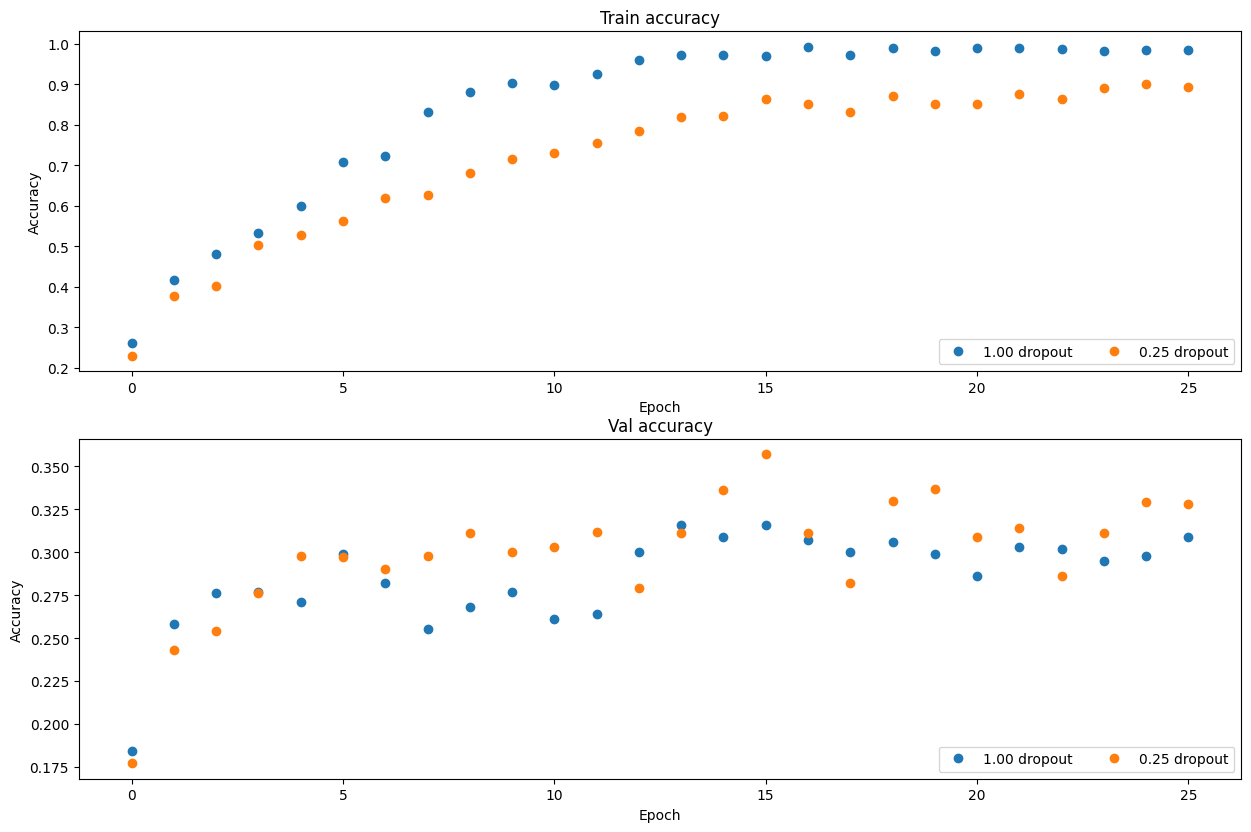

In [47]:
# Plot train and validation accuracies of the two models

train_accs = []
val_accs = []
for dropout in dropout_choices:
  solver = solvers[dropout]
  train_accs.append(solver.train_acc_history[-1])
  val_accs.append(solver.val_acc_history[-1])

plt.subplot(3, 1, 1)
for dropout in dropout_choices:
  plt.plot(solvers[dropout].train_acc_history, 'o', label='%.2f dropout' % dropout)
plt.title('Train accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(ncol=2, loc='lower right')
  
plt.subplot(3, 1, 2)
for dropout in dropout_choices:
  plt.plot(solvers[dropout].val_acc_history, 'o', label='%.2f dropout' % dropout)
plt.title('Val accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(ncol=2, loc='lower right')

plt.gcf().set_size_inches(15, 15)
plt.show()

**Выводы.** Без dropout сеть почти полностью запоминает 500 обучающих картинок (train ≈ 0.98), а val держится около 0.30, то есть переобучение сильное. С dropout (p=0.25) accuracy на train ниже (≈0.89), а на val выше (лучшая 0.357 против 0.316). Разрыв между train и val уменьшился, значит dropout работает как регуляризация и снижает переобучение.

# Лучшая полносвязная сеть

Этот раздел выполняется после разделов про батч-нормализацию и dropout, так как лучшая модель использует оба приёма.

Получите лучшую полносвязную сеть для классификации вашего набора данных. На наборе CIFAR-10 необходимо получить accuracy не ниже 50 % на валидационном наборе.

In [48]:
best_model = None

# 3 скрытых слоя по 256 нейронов + батч-нормализация + dropout, оптимизатор Adam
np.random.seed(231)
best_model = FullyConnectedNet([256, 256, 256], weight_scale=2e-2,
                               normalization='batchnorm', dropout=0.75, reg=1e-3)
best_solver = Solver(best_model, data,
                     num_epochs=12, batch_size=200,
                     update_rule='adam',
                     optim_config={'learning_rate': 1e-3},
                     lr_decay=0.9,
                     print_every=1000, verbose=True)
best_solver.train()
print('Best validation accuracy: ', best_solver.best_val_acc)

(Iteration 1 / 2940) loss: 2.529453
(Epoch 0 / 12) train acc: 0.128000; val_acc: 0.149000
(Epoch 1 / 12) train acc: 0.474000; val_acc: 0.482000
(Epoch 2 / 12) train acc: 0.492000; val_acc: 0.501000
(Epoch 3 / 12) train acc: 0.502000; val_acc: 0.516000
(Epoch 4 / 12) train acc: 0.533000; val_acc: 0.517000
(Iteration 1001 / 2940) loss: 1.473284
(Epoch 5 / 12) train acc: 0.575000; val_acc: 0.539000
(Epoch 6 / 12) train acc: 0.560000; val_acc: 0.530000
(Epoch 7 / 12) train acc: 0.624000; val_acc: 0.559000
(Epoch 8 / 12) train acc: 0.588000; val_acc: 0.565000
(Iteration 2001 / 2940) loss: 1.363148
(Epoch 9 / 12) train acc: 0.604000; val_acc: 0.583000
(Epoch 10 / 12) train acc: 0.648000; val_acc: 0.573000
(Epoch 11 / 12) train acc: 0.644000; val_acc: 0.568000
(Epoch 12 / 12) train acc: 0.648000; val_acc: 0.589000
Best validation accuracy:  0.589


Получите оценку accuracy для валидационной и тестовой выборок. 

In [49]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Validation set accuracy: ', (y_val_pred == data['y_val']).mean())
print('Test set accuracy: ', (y_test_pred == data['y_test']).mean())

Validation set accuracy:  0.589
Test set accuracy:  0.556


**Выводы.** Лучшая полносвязная сеть: 3 скрытых слоя по 256 нейронов, батч-нормализация, dropout (p=0.75), L2 reg=1e-3, Adam (lr=1e-3, lr_decay=0.9), 12 эпох, батч 200. Accuracy на валидации **0.589**, на тесте **0.556**. Это выше требуемых 50% и выше двухслойной сети (0.512).

# Сверточные нейронные сети (CNN)

Реализуйте прямой проход для сверточного слоя - функция conv_forward_naive. Проверьте свою реализацию, запустив код ниже 

In [50]:
def conv_forward_naive(x, w, b, conv_param):
    """
    Прямой проход свёрточного слоя.
    x: (N, C, H, W), w: (F, C, HH, WW), b: (F,)
    conv_param: stride, pad
    out: (N, F, H', W'),  H' = 1 + (H + 2 * pad - HH) / stride
    """
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    stride, pad = conv_param['stride'], conv_param['pad']

    H_out = 1 + (H + 2 * pad - HH) // stride
    W_out = 1 + (W + 2 * pad - WW) // stride

    # дополняем нулями только по высоте и ширине (x не меняем)
    x_pad = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)), mode='constant')
    out = np.zeros((N, F, H_out, W_out), dtype=x.dtype)

    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            window = x_pad[:, :, hs:hs + HH, ws:ws + WW]          # (N, C, HH, WW)
            # скалярное произведение окна с каждым фильтром
            out[:, :, i, j] = np.tensordot(window, w, axes=([1, 2, 3], [1, 2, 3])) + b

    cache = (x, w, b, conv_param)
    return out, cache

In [ ]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)

conv_param = {'stride': 2, 'pad': 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array([[[[-0.08759809, -0.10987781],
                           [-0.18387192, -0.2109216 ]],
                          [[ 0.21027089,  0.21661097],
                           [ 0.22847626,  0.23004637]],
                          [[ 0.50813986,  0.54309974],
                           [ 0.64082444,  0.67101435]]],
                         [[[-0.98053589, -1.03143541],
                           [-1.19128892, -1.24695841]],
                          [[ 0.69108355,  0.66880383],
                           [ 0.59480972,  0.56776003]],
                          [[ 2.36270298,  2.36904306],
                           [ 2.38090835,  2.38247847]]]])

print('Testing conv_forward_naive')
print('difference: ', rel_error(out, correct_out))

Testing conv_forward_naive
difference:  2.2121476575931688e-08


Реализуйте обратный проход - функция conv_backward_naive

In [52]:
def conv_backward_naive(dout, cache):
    """
    Обратный проход свёрточного слоя.
    dout: (N, F, H', W')  ->  dx, dw, db
    """
    x, w, b, conv_param = cache
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    stride, pad = conv_param['stride'], conv_param['pad']
    _, _, H_out, W_out = dout.shape

    x_pad = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)), mode='constant')
    dx_pad = np.zeros_like(x_pad)
    dw = np.zeros_like(w)
    db = np.sum(dout, axis=(0, 2, 3))

    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            window = x_pad[:, :, hs:hs + HH, ws:ws + WW]
            d = dout[:, :, i, j]                                   # (N, F)
            dw += np.tensordot(d, window, axes=([0], [0]))         # (F, C, HH, WW)
            dx_pad[:, :, hs:hs + HH, ws:ws + WW] += np.tensordot(d, w, axes=([1], [0]))

    # убираем паддинг
    dx = dx_pad[:, :, pad:pad + H, pad:pad + W]
    return dx, dw, db

In [ ]:
np.random.seed(231)
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2,)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {'stride': 1, 'pad': 1}

dx_num = eval_numerical_gradient_array(lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout)

out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)

print('Testing conv_backward_naive function')
print('dx error: ', rel_error(dx, dx_num))
print('dw error: ', rel_error(dw, dw_num))
print('db error: ', rel_error(db, db_num))

Testing conv_backward_naive function
dx error:  7.99015495883212e-09
dw error:  2.6782772496622533e-10
db error:  3.8835192329918934e-11


Реализуйте прямой проход для max-pooling слоя -функция max_pool_forward_naive

In [54]:
def max_pool_forward_naive(x, pool_param):
    """
    Max-pooling: максимум в каждом окне pool_height x pool_width.
    out: (N, C, H', W'),  H' = 1 + (H - pool_height) / stride
    """
    N, C, H, W = x.shape
    ph, pw = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']

    H_out = 1 + (H - ph) // stride
    W_out = 1 + (W - pw) // stride
    out = np.zeros((N, C, H_out, W_out), dtype=x.dtype)

    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            out[:, :, i, j] = np.max(x[:, :, hs:hs + ph, ws:ws + pw], axis=(2, 3))

    cache = (x, pool_param)
    return out, cache

In [ ]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {'pool_width': 2, 'pool_height': 2, 'stride': 2}

out, _ = max_pool_forward_naive(x, pool_param)

correct_out = np.array([[[[-0.26315789, -0.24842105],
                          [-0.20421053, -0.18947368]],
                         [[-0.14526316, -0.13052632],
                          [-0.08631579, -0.07157895]],
                         [[-0.02736842, -0.01263158],
                          [ 0.03157895,  0.04631579]]],
                        [[[ 0.09052632,  0.10526316],
                          [ 0.14947368,  0.16421053]],
                         [[ 0.20842105,  0.22315789],
                          [ 0.26736842,  0.28210526]],
                         [[ 0.32631579,  0.34105263],
                          [ 0.38526316,  0.4       ]]]])

print('Testing max_pool_forward_naive function:')
print('difference: ', rel_error(out, correct_out))

Testing max_pool_forward_naive function:
difference:  4.1666665157267834e-08


Реализуйте обратный проход для max-pooling слоя в max_pool_backward_naive . 

In [56]:
def max_pool_backward_naive(dout, cache):
    """ градиент из каждого окна идёт только в тот элемент, где был максимум """
    x, pool_param = cache
    N, C, H, W = x.shape
    ph, pw = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']
    _, _, H_out, W_out = dout.shape

    dx = np.zeros_like(x)
    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            window = x[:, :, hs:hs + ph, ws:ws + pw].reshape(N, C, -1)
            idx = np.argmax(window, axis=2)                       # позиция максимума
            mask = np.zeros_like(window)
            np.put_along_axis(mask, idx[:, :, None], 1, axis=2)
            dx[:, :, hs:hs + ph, ws:ws + pw] += \
                mask.reshape(N, C, ph, pw) * dout[:, :, i, j][:, :, None, None]
    return dx

In [ ]:
np.random.seed(231)
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

dx_num = eval_numerical_gradient_array(lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout)

out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)

print('Testing max_pool_backward_naive function:')
print('dx error: ', rel_error(dx, dx_num))

Testing max_pool_backward_naive function:
dx error:  3.27562514223145e-12


В исходном варианте быстрые слои (`fast_layers.py`) используют Cython-модуль `im2col_cython`, который нужно
компилировать (`python setup.py build_ext --inplace`). Здесь вспомогательные функции `im2col` / `col2im`
написаны на numpy, поэтому компиляция не нужна:

- свёртка: `conv_forward_strides` строит матрицу окон через `np.lib.stride_tricks.as_strided`, после чего
  свёртка сводится к одному умножению матриц; в обратном проходе окна суммируются обратно в изображение (`col2im_6d`);
- max-pooling: если окна не перекрываются и покрывают картинку целиком, используется быстрый вариант через `reshape`,
  иначе - через `im2col`.

In [58]:
# --- im2col.py ---
def get_im2col_indices(x_shape, field_height, field_width, padding=1, stride=1):
    N, C, H, W = x_shape
    assert (H + 2 * padding - field_height) % stride == 0
    assert (W + 2 * padding - field_width) % stride == 0
    out_height = (H + 2 * padding - field_height) // stride + 1
    out_width = (W + 2 * padding - field_width) // stride + 1

    i0 = np.repeat(np.arange(field_height), field_width)
    i0 = np.tile(i0, C)
    i1 = stride * np.repeat(np.arange(out_height), out_width)
    j0 = np.tile(np.arange(field_width), field_height * C)
    j1 = stride * np.tile(np.arange(out_width), out_height)
    i = i0.reshape(-1, 1) + i1.reshape(1, -1)
    j = j0.reshape(-1, 1) + j1.reshape(1, -1)

    k = np.repeat(np.arange(C), field_height * field_width).reshape(-1, 1)

    return (k, i, j)


def im2col_indices(x, field_height, field_width, padding=1, stride=1):
    """ im2col через индексацию: каждое окно -> столбец матрицы """
    p = padding
    x_padded = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p)), mode='constant')

    k, i, j = get_im2col_indices(x.shape, field_height, field_width, padding, stride)

    cols = x_padded[:, k, i, j]
    C = x.shape[1]
    cols = cols.transpose(1, 2, 0).reshape(field_height * field_width * C, -1)
    return cols


def col2im_indices(cols, x_shape, field_height=3, field_width=3, padding=1, stride=1):
    """ обратная операция: столбцы раскладываются по окнам, перекрытия суммируются """
    N, C, H, W = x_shape
    H_padded, W_padded = H + 2 * padding, W + 2 * padding
    x_padded = np.zeros((N, C, H_padded, W_padded), dtype=cols.dtype)
    k, i, j = get_im2col_indices(x_shape, field_height, field_width, padding, stride)
    cols_reshaped = cols.reshape(C * field_height * field_width, -1, N)
    cols_reshaped = cols_reshaped.transpose(2, 0, 1)
    np.add.at(x_padded, (slice(None), k, i, j), cols_reshaped)
    if padding == 0:
        return x_padded
    return x_padded[:, :, padding:-padding, padding:-padding]


def col2im_6d(cols, N, C, H, W, HH, WW, pad, stride):
    """
    numpy-версия col2im_6d_cython.
    cols: (C, HH, WW, N, out_h, out_w) -> dx: (N, C, H, W)
    Цикл только по позициям внутри фильтра (HH * WW итераций),
    остальное делается срезами.
    """
    out_h = (H + 2 * pad - HH) // stride + 1
    out_w = (W + 2 * pad - WW) // stride + 1
    x_padded = np.zeros((N, C, H + 2 * pad, W + 2 * pad), dtype=cols.dtype)
    for hh in range(HH):
        for ww in range(WW):
            x_padded[:, :, hh:hh + stride * out_h:stride, ww:ww + stride * out_w:stride] += \
                cols[:, hh, ww].transpose(1, 0, 2, 3)
    if pad > 0:
        return x_padded[:, :, pad:-pad, pad:-pad]
    return x_padded


# --- fast_layers.py ---
def conv_forward_strides(x, w, b, conv_param):
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    stride, pad = conv_param['stride'], conv_param['pad']

    p = pad
    x_padded = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p)), mode='constant')

    H += 2 * pad
    W += 2 * pad
    out_h = (H - HH) // stride + 1
    out_w = (W - WW) // stride + 1

    # im2col без копирования: окна получаем подбором шагов (strides) по памяти
    shape = (C, HH, WW, N, out_h, out_w)
    strides = (H * W, W, 1, C * H * W, stride * W, stride)
    strides = x_padded.itemsize * np.array(strides)
    x_stride = np.lib.stride_tricks.as_strided(x_padded, shape=shape, strides=strides)
    x_cols = np.ascontiguousarray(x_stride)
    x_cols.shape = (C * HH * WW, N * out_h * out_w)

    # вся свёртка - одно матричное умножение
    res = w.reshape(F, -1).dot(x_cols) + b.reshape(-1, 1)

    res.shape = (F, N, out_h, out_w)
    out = res.transpose(1, 0, 2, 3)
    out = np.ascontiguousarray(out)

    cache = (x, w, b, conv_param, x_cols)
    return out, cache


def conv_backward_strides(dout, cache):
    x, w, b, conv_param, x_cols = cache
    stride, pad = conv_param['stride'], conv_param['pad']

    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    _, _, out_h, out_w = dout.shape

    db = np.sum(dout, axis=(0, 2, 3))

    dout_reshaped = dout.transpose(1, 0, 2, 3).reshape(F, -1)
    dw = dout_reshaped.dot(x_cols.T).reshape(w.shape)

    dx_cols = w.reshape(F, -1).T.dot(dout_reshaped)
    dx_cols.shape = (C, HH, WW, N, out_h, out_w)
    dx = col2im_6d(dx_cols, N, C, H, W, HH, WW, pad, stride)

    return dx, dw, db


conv_forward_fast = conv_forward_strides
conv_backward_fast = conv_backward_strides


def max_pool_forward_reshape(x, pool_param):
    """ быстрый max-pooling для неперекрывающихся квадратных окон """
    N, C, H, W = x.shape
    pool_height, pool_width = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']
    assert pool_height == pool_width == stride, 'Invalid pool params'
    assert H % pool_height == 0
    assert W % pool_height == 0
    x_reshaped = x.reshape(N, C, H // pool_height, pool_height, W // pool_width, pool_width)
    out = x_reshaped.max(axis=3).max(axis=4)

    cache = (x, x_reshaped, out)
    return out, cache


def max_pool_backward_reshape(dout, cache):
    x, x_reshaped, out = cache

    dx_reshaped = np.zeros_like(x_reshaped)
    out_newaxis = out[:, :, :, np.newaxis, :, np.newaxis]
    mask = x_reshaped == out_newaxis
    dout_newaxis = dout[:, :, :, np.newaxis, :, np.newaxis]
    dout_broadcast, _ = np.broadcast_arrays(dout_newaxis, dx_reshaped)
    dx_reshaped[mask] = dout_broadcast[mask]
    # если максимумов в окне несколько, делим градиент между ними
    dx_reshaped /= np.sum(mask, axis=(3, 5), keepdims=True)
    dx = dx_reshaped.reshape(x.shape)

    return dx


def max_pool_forward_im2col(x, pool_param):
    N, C, H, W = x.shape
    pool_height, pool_width = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']

    assert (H - pool_height) % stride == 0, 'Invalid height'
    assert (W - pool_width) % stride == 0, 'Invalid width'

    out_height = (H - pool_height) // stride + 1
    out_width = (W - pool_width) // stride + 1

    x_split = x.reshape(N * C, 1, H, W)
    x_cols = im2col_indices(x_split, pool_height, pool_width, padding=0, stride=stride)
    x_cols_argmax = np.argmax(x_cols, axis=0)
    x_cols_max = x_cols[x_cols_argmax, np.arange(x_cols.shape[1])]
    out = x_cols_max.reshape(out_height, out_width, N, C).transpose(2, 3, 0, 1)

    cache = (x, x_cols, x_cols_argmax, pool_param)
    return out, cache


def max_pool_backward_im2col(dout, cache):
    x, x_cols, x_cols_argmax, pool_param = cache
    N, C, H, W = x.shape
    pool_height, pool_width = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']

    dout_reshaped = dout.transpose(2, 3, 0, 1).flatten()
    dx_cols = np.zeros_like(x_cols)
    dx_cols[x_cols_argmax, np.arange(dx_cols.shape[1])] = dout_reshaped
    dx = col2im_indices(dx_cols, (N * C, 1, H, W), pool_height, pool_width,
                        padding=0, stride=stride)
    dx = dx.reshape(x.shape)

    return dx


def max_pool_forward_fast(x, pool_param):
    """ выбирает reshape-вариант, если окна не перекрываются, иначе im2col """
    N, C, H, W = x.shape
    pool_height, pool_width = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']

    same_size = pool_height == pool_width == stride
    tiles = H % pool_height == 0 and W % pool_width == 0
    if same_size and tiles:
        out, reshape_cache = max_pool_forward_reshape(x, pool_param)
        cache = ('reshape', reshape_cache)
    else:
        out, im2col_cache = max_pool_forward_im2col(x, pool_param)
        cache = ('im2col', im2col_cache)
    return out, cache


def max_pool_backward_fast(dout, cache):
    method, real_cache = cache
    if method == 'reshape':
        return max_pool_backward_reshape(dout, real_cache)
    elif method == 'im2col':
        return max_pool_backward_im2col(dout, real_cache)
    else:
        raise ValueError('Unrecognized method "%s"' % method)

Сравните ваши реализации слоев свертки и пуллинга с быстрыми реализациями.

In [ ]:
np.random.seed(231)
x = np.random.randn(100, 3, 31, 31)
w = np.random.randn(25, 3, 3, 3)
b = np.random.randn(25,)
dout = np.random.randn(100, 25, 16, 16)
conv_param = {'stride': 2, 'pad': 1}

t0 = time()
out_naive, cache_naive = conv_forward_naive(x, w, b, conv_param)
t1 = time()
out_fast, cache_fast = conv_forward_fast(x, w, b, conv_param)
t2 = time()

print('Testing conv_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('Difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive, dw_naive, db_naive = conv_backward_naive(dout, cache_naive)
t1 = time()
dx_fast, dw_fast, db_fast = conv_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting conv_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))
print('dw difference: ', rel_error(dw_naive, dw_fast))
print('db difference: ', rel_error(db_naive, db_fast))

Testing conv_forward_fast:
Naive: 0.047354s
Fast: 0.012318s
Speedup: 3.844156x
Difference:  3.267006617452843e-13

Testing conv_backward_fast:
Naive: 0.088671s
Fast: 0.020491s
Speedup: 4.327326x
dx difference:  5.021244662145216e-13
dw difference:  8.261743907975454e-14
db difference:  0.0


In [ ]:
np.random.seed(231)
x = np.random.randn(100, 3, 32, 32)
dout = np.random.randn(100, 3, 16, 16)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

t0 = time()
out_naive, cache_naive = max_pool_forward_naive(x, pool_param)
t1 = time()
out_fast, cache_fast = max_pool_forward_fast(x, pool_param)
t2 = time()

print('Testing pool_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive = max_pool_backward_naive(dout, cache_naive)
t1 = time()
dx_fast = max_pool_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting pool_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))

Testing pool_forward_fast:
Naive: 0.016009s
fast: 0.007948s
speedup: 2.014279x
difference:  0.0

Testing pool_backward_fast:
Naive: 0.034003s
fast: 0.017821s
speedup: 1.908035x
dx difference:  0.0


**Выводы.** Результаты быстрых реализаций совпадают с наивными (разница ~1e-13, у пулинга 0). Быстрая свёртка примерно в 4 раза быстрее наивной, пулинг примерно в 2 раза. Наивная версия здесь уже частично векторизована (цикл только по позициям выхода), поэтому выигрыш меньше, чем был бы по сравнению с полностью «циклической» реализацией.

Ниже приведены часто используемые комбинации слоев, используемых в сверточных сетях. Ознакомьтесь с ними и запустите код ниже для проверки их работы

In [61]:
def spatial_batchnorm_forward(x, gamma, beta, bn_param):
    """
    Батч-нормализация для свёрточных слоёв: статистики считаются по каждому каналу
    сразу по N, H и W. Сводится к обычной batchnorm, если переставить оси (N, H, W, C).
    """
    N, C, H, W = x.shape
    x_flat = x.transpose(0, 2, 3, 1).reshape(-1, C)
    out_flat, cache = batchnorm_forward(x_flat, gamma, beta, bn_param)
    out = out_flat.reshape(N, H, W, C).transpose(0, 3, 1, 2)
    return out, cache


def spatial_batchnorm_backward(dout, cache):
    N, C, H, W = dout.shape
    dout_flat = dout.transpose(0, 2, 3, 1).reshape(-1, C)
    dx_flat, dgamma, dbeta = batchnorm_backward(dout_flat, cache)
    dx = dx_flat.reshape(N, H, W, C).transpose(0, 3, 1, 2)
    return dx, dgamma, dbeta


def spatial_groupnorm_forward(x, gamma, beta, G, gn_param):
    """
    Group normalization: каналы каждого примера делятся на G групп,
    каждая группа нормируется отдельно (не зависит от размера батча).
    """
    eps = gn_param.get('eps', 1e-5)
    N, C, H, W = x.shape
    xg = x.reshape(N, G, -1)
    mean = xg.mean(axis=2, keepdims=True)
    std = np.sqrt(xg.var(axis=2, keepdims=True) + eps)
    x_hat = ((xg - mean) / std).reshape(N, C, H, W)

    g = gamma.reshape(1, C, 1, 1)
    b = beta.reshape(1, C, 1, 1)
    out = g * x_hat + b

    cache = (x_hat, gamma, std, G)
    return out, cache


def spatial_groupnorm_backward(dout, cache):
    x_hat, gamma, std, G = cache
    N, C, H, W = dout.shape

    dbeta = np.sum(dout, axis=(0, 2, 3)).reshape(gamma.shape)
    dgamma = np.sum(dout * x_hat, axis=(0, 2, 3)).reshape(gamma.shape)

    # внутри группы формула та же, что и у batchnorm, только усреднение по M элементам группы
    dx_hat = (dout * gamma.reshape(1, C, 1, 1)).reshape(N, G, -1)
    xh = x_hat.reshape(N, G, -1)
    M = xh.shape[2]
    dx = (M * dx_hat - dx_hat.sum(axis=2, keepdims=True)
          - xh * np.sum(dx_hat * xh, axis=2, keepdims=True)) / (M * std)
    dx = dx.reshape(N, C, H, W)

    return dx, dgamma, dbeta

In [62]:
def conv_relu_forward(x, w, b, conv_param):
    """ conv -> ReLU """
    a, conv_cache = conv_forward_fast(x, w, b, conv_param)
    out, relu_cache = relu_forward(a)
    cache = (conv_cache, relu_cache)
    return out, cache


def conv_relu_backward(dout, cache):
    conv_cache, relu_cache = cache
    da = relu_backward(dout, relu_cache)
    dx, dw, db = conv_backward_fast(da, conv_cache)
    return dx, dw, db


def conv_bn_relu_forward(x, w, b, gamma, beta, conv_param, bn_param):
    """ conv -> spatial batchnorm -> ReLU """
    a, conv_cache = conv_forward_fast(x, w, b, conv_param)
    an, bn_cache = spatial_batchnorm_forward(a, gamma, beta, bn_param)
    out, relu_cache = relu_forward(an)
    cache = (conv_cache, bn_cache, relu_cache)
    return out, cache


def conv_bn_relu_backward(dout, cache):
    conv_cache, bn_cache, relu_cache = cache
    dan = relu_backward(dout, relu_cache)
    da, dgamma, dbeta = spatial_batchnorm_backward(dan, bn_cache)
    dx, dw, db = conv_backward_fast(da, conv_cache)
    return dx, dw, db, dgamma, dbeta


def conv_relu_pool_forward(x, w, b, conv_param, pool_param):
    """ conv -> ReLU -> max pool """
    a, conv_cache = conv_forward_fast(x, w, b, conv_param)
    s, relu_cache = relu_forward(a)
    out, pool_cache = max_pool_forward_fast(s, pool_param)
    cache = (conv_cache, relu_cache, pool_cache)
    return out, cache


def conv_relu_pool_backward(dout, cache):
    conv_cache, relu_cache, pool_cache = cache
    ds = max_pool_backward_fast(dout, pool_cache)
    da = relu_backward(ds, relu_cache)
    dx, dw, db = conv_backward_fast(da, conv_cache)
    return dx, dw, db

In [ ]:
np.random.seed(231)
x = np.random.randn(2, 3, 16, 16)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

out, cache = conv_relu_pool_forward(x, w, b, conv_param, pool_param)
dx, dw, db = conv_relu_pool_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], b, dout)

print('Testing conv_relu_pool')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu_pool
dx error:  9.591132621921372e-09
dw error:  5.802401370096438e-09
db error:  1.0146343411762047e-09


In [ ]:
np.random.seed(231)
x = np.random.randn(2, 3, 8, 8)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}

out, cache = conv_relu_forward(x, w, b, conv_param)
dx, dw, db = conv_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_forward(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_forward(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_forward(x, w, b, conv_param)[0], b, dout)

print('Testing conv_relu:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu:
dx error:  1.5218619980349303e-09
dw error:  2.702022646099404e-10
db error:  1.451272393591721e-10


Напишите реализацию класса ThreeLayerConvNet. Вы можете использовать готовые реализации слоев и их комбинаций.

Проверьте вашу реализацию. Ожидается, что значение функции потерь softmax будет порядка `log(C)` для `C` классов для случая без регуляризации. В случае регуляризации значение функции потерь должно немного возрасти. 

In [65]:
class ThreeLayerConvNet(object):
    """
    Трёхслойная свёрточная сеть:

    conv - relu - 2x2 max pool - affine - relu - affine - softmax

    Вход: (N, C, H, W).
    """

    def __init__(self, input_dim=(3, 32, 32), num_filters=32, filter_size=7,
                 hidden_dim=100, num_classes=10, weight_scale=1e-3, reg=0.0,
                 dtype=np.float32):
        self.params = {}
        self.reg = reg
        self.dtype = dtype

        C, H, W = input_dim
        # свёртка сохраняет H и W (stride=1, pad=(filter_size-1)/2),
        # а pooling 2x2 уменьшает их вдвое
        pooled_dim = num_filters * (H // 2) * (W // 2)

        self.params['W1'] = weight_scale * np.random.randn(num_filters, C, filter_size, filter_size)
        self.params['b1'] = np.zeros(num_filters)
        self.params['W2'] = weight_scale * np.random.randn(pooled_dim, hidden_dim)
        self.params['b2'] = np.zeros(hidden_dim)
        self.params['W3'] = weight_scale * np.random.randn(hidden_dim, num_classes)
        self.params['b3'] = np.zeros(num_classes)

        for k, v in self.params.items():
            self.params[k] = v.astype(dtype)

    def loss(self, X, y=None):
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        W3, b3 = self.params['W3'], self.params['b3']

        filter_size = W1.shape[2]
        conv_param = {'stride': 1, 'pad': (filter_size - 1) // 2}
        pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

        # прямой проход
        out1, cache1 = conv_relu_pool_forward(X, W1, b1, conv_param, pool_param)
        out2, cache2 = affine_relu_forward(out1, W2, b2)
        scores, cache3 = affine_forward(out2, W3, b3)

        if y is None:
            return scores

        loss, grads = 0, {}
        loss, dscores = softmax_loss(scores, y)
        loss += 0.5 * self.reg * (np.sum(W1 * W1) + np.sum(W2 * W2) + np.sum(W3 * W3))

        # обратный проход
        dout2, grads['W3'], grads['b3'] = affine_backward(dscores, cache3)
        dout1, grads['W2'], grads['b2'] = affine_relu_backward(dout2, cache2)
        _, grads['W1'], grads['b1'] = conv_relu_pool_backward(dout1, cache1)

        grads['W3'] += self.reg * W3
        grads['W2'] += self.reg * W2
        grads['W1'] += self.reg * W1

        return loss, grads

In [66]:
model = ThreeLayerConvNet()

N = 50
X = np.random.randn(N, 3, 32, 32)
y = np.random.randint(10, size=N)

loss, grads = model.loss(X, y)
print('Initial loss (no regularization): ', loss)

model.reg = 0.5
loss, grads = model.loss(X, y)
print('Initial loss (with regularization): ', loss)

Initial loss (no regularization):  2.302586071243987
Initial loss (with regularization):  2.508255638232932


Проверьте реализацию обратного прохода

In [ ]:
num_inputs = 2
input_dim = (3, 16, 16)
reg = 0.0
num_classes = 10
np.random.seed(231)
X = np.random.randn(num_inputs, *input_dim)
y = np.random.randint(num_classes, size=num_inputs)

model = ThreeLayerConvNet(num_filters=3, filter_size=3,
                          input_dim=input_dim, hidden_dim=7,
                          dtype=np.float64)
loss, grads = model.loss(X, y)

for param_name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    param_grad_num = eval_numerical_gradient(f, model.params[param_name], verbose=False, h=1e-6)
    e = rel_error(param_grad_num, grads[param_name])
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W1 max relative error: 1.380104e-04
W2 max relative error: 1.822723e-02
W3 max relative error: 3.064049e-04
b1 max relative error: 3.477652e-05
b2 max relative error: 2.516375e-03
b3 max relative error: 7.945660e-10


Попробуйте добиться эффекта переобучения. Обучите модель на небольшом наборе данных.Сравните значения accuracy на обучающих данных и на валидационных. Визуализируйте графики обучения 

In [68]:
np.random.seed(231)

num_train = 100
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

model = ThreeLayerConvNet(weight_scale=1e-2)

solver = Solver(model, small_data,
                num_epochs=15, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=1)
solver.train()

(Iteration 1 / 30) loss: 2.414060
(Epoch 0 / 15) train acc: 0.200000; val_acc: 0.137000
(Iteration 2 / 30) loss: 3.102925
(Epoch 1 / 15) train acc: 0.140000; val_acc: 0.087000
(Iteration 3 / 30) loss: 2.270330
(Iteration 4 / 30) loss: 2.096705
(Epoch 2 / 15) train acc: 0.240000; val_acc: 0.094000
(Iteration 5 / 30) loss: 1.838880
(Iteration 6 / 30) loss: 1.934188
(Epoch 3 / 15) train acc: 0.510000; val_acc: 0.173000
(Iteration 7 / 30) loss: 1.827912
(Iteration 8 / 30) loss: 1.639574
(Epoch 4 / 15) train acc: 0.520000; val_acc: 0.188000
(Iteration 9 / 30) loss: 1.330082
(Iteration 10 / 30) loss: 1.756115
(Epoch 5 / 15) train acc: 0.630000; val_acc: 0.167000
(Iteration 11 / 30) loss: 1.024162
(Iteration 12 / 30) loss: 1.041826
(Epoch 6 / 15) train acc: 0.750000; val_acc: 0.229000
(Iteration 13 / 30) loss: 1.142777
(Iteration 14 / 30) loss: 0.835706
(Epoch 7 / 15) train acc: 0.790000; val_acc: 0.247000
(Iteration 15 / 30) loss: 0.587786
(Iteration 16 / 30) loss: 0.645509
(Epoch 8 / 15) tr

In [69]:
# Print final training accuracy
print(
    "Small data training accuracy:",
    solver.check_accuracy(small_data['X_train'], small_data['y_train'])
)

Small data training accuracy: 0.82


In [70]:
# Print final validation accuracy
print(
    "Small data validation accuracy:",
    solver.check_accuracy(small_data['X_val'], small_data['y_val'])
)

Small data validation accuracy: 0.252


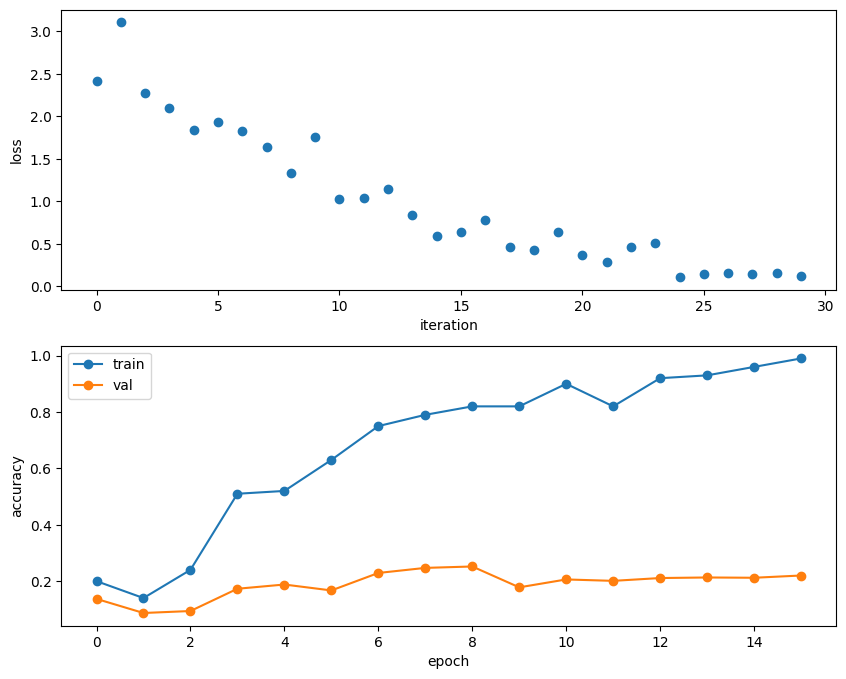

In [71]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, 'o')
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(['train', 'val'], loc='upper left')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

**Выводы.** - Начальный loss без регуляризации равен 2.3026 ≈ log(10), как и ожидается для 10 классов. С регуляризацией loss немного больше (2.51).
- Численная проверка градиентов проходит: ошибки не больше ~1e-2, что допустимо по условию.
- На 100 картинках сеть сильно переобучается: к 15-й эпохе train accuracy ≈ 0.99, а val всего ≈ 0.2-0.25.
- Итоговая train accuracy после обучения (0.82) ниже, чем на последней эпохе. Причина: Solver в конце возвращает веса с лучшей accuracy на валидации (8-я эпоха), а не с последней.

Обучите сеть на полном наборе данных. Выведите accuracy на обучающей и валидационной выборках

In [72]:
model = ThreeLayerConvNet(weight_scale=0.001, hidden_dim=500, reg=0.001)

solver = Solver(model, data,
                num_epochs=1, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20)
solver.train()

(Iteration 1 / 980) loss: 2.304740
(Epoch 0 / 1) train acc: 0.103000; val_acc: 0.107000
(Iteration 21 / 980) loss: 2.098229
(Iteration 41 / 980) loss: 1.949788
(Iteration 61 / 980) loss: 1.888398
(Iteration 81 / 980) loss: 1.877093
(Iteration 101 / 980) loss: 1.851877
(Iteration 121 / 980) loss: 1.859353
(Iteration 141 / 980) loss: 1.800181
(Iteration 161 / 980) loss: 2.143292
(Iteration 181 / 980) loss: 1.830573
(Iteration 201 / 980) loss: 2.037280
(Iteration 221 / 980) loss: 2.020304
(Iteration 241 / 980) loss: 1.823728
(Iteration 261 / 980) loss: 1.692679
(Iteration 281 / 980) loss: 1.882594
(Iteration 301 / 980) loss: 1.798261
(Iteration 321 / 980) loss: 1.851960
(Iteration 341 / 980) loss: 1.716323
(Iteration 361 / 980) loss: 1.897655
(Iteration 381 / 980) loss: 1.319744
(Iteration 401 / 980) loss: 1.738790
(Iteration 421 / 980) loss: 1.488866
(Iteration 441 / 980) loss: 1.718409
(Iteration 461 / 980) loss: 1.744440
(Iteration 481 / 980) loss: 1.605460
(Iteration 501 / 980) loss: 

In [73]:
# Print final training accuracy
print(
    "Full data training accuracy:",
    solver.check_accuracy(data['X_train'], data['y_train'])
)

Full data training accuracy: 0.4761836734693878


In [74]:
# Print final validation accuracy
print(
    "Full data validation accuracy:",
    solver.check_accuracy(data['X_val'], data['y_val'])
)

Full data validation accuracy: 0.499


**Выводы.** Всего за 1 эпоху на полном наборе свёрточная сеть достигает accuracy **0.476** на train и **0.499** на val. Двухслойной полносвязной сети для такого результата понадобилось 10 эпох. Train и val близки, переобучения нет, и при большем числе эпох качество будет расти дальше. Фильтры первого слоя похожи на детекторы цветовых пятен и краёв разной ориентации.

Визуализируйте фильтры на первом слое обученной сети

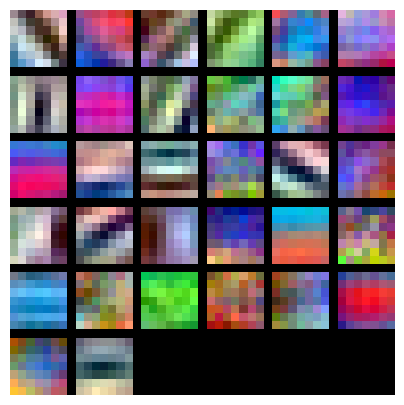

In [75]:

grid = visualize_grid(model.params['W1'].transpose(0, 2, 3, 1))
plt.imshow(grid.astype('uint8'))
plt.axis('off')
plt.gcf().set_size_inches(5, 5)
plt.show()

## Общие выводы

1. Реализованы все слои: полносвязный, ReLU, батч-нормализация (обычная, пространственная и групповая), dropout, свёртка, max-pooling, а также быстрые версии свёртки и пулинга через im2col. Прямые и обратные проходы проверены численным градиентом.
2. Реализованы правила обновления SGD, SGD+momentum, RMSProp и Adam. Адаптивные методы и импульс сходятся заметно быстрее обычного SGD.
3. Батч-нормализация ускоряет обучение глубоких сетей, но плохо работает с маленькими батчами. Dropout уменьшает переобучение.
4. Лучшая полносвязная сеть на CIFAR-10 даёт **0.589** на валидации и **0.556** на тесте.
5. Свёрточная сеть уже за одну эпоху даёт ≈ 0.50 на валидации, потому что учитывает пространственную структуру изображения. Для картинок это лучший выбор, чем полносвязная сеть.